In [1]:
import numpy as np
import pandas as pd
import geopandas as gpd

In [2]:
rivers = gpd.read_file("data/main_rivers.gpkg", layer="main_rivers")
grid = gpd.read_file("overall_species_grid_005_pixels.gpkg")

In [12]:
rivers

,OBJECTID,HYRIV_ID,NEXT_DOWN,MAIN_RIV,LENGTH_KM,DIST_DN_KM,DIST_UP_KM,CATCH_SKM,UPLAND_SKM,ENDORHEIC,DIS_AV_CMS,ORD_STRA,ORD_CLAS,ORD_FLOW,HYBAS_L12,Shape_Length,geometry
0,731738,10731738,10731138,10877687,1.58,1665.300049,176.000000,2.980000,6847.200195,0,104.730003,5,4,4,1.120910e+09,0.014226,"MULTILINESTRING Z ((13.28125 7.70208 0, 13.283..."
1,733400,10733400,10731738,10877687,6.30,1666.800049,174.399994,25.950001,6664.100098,0,102.146004,5,4,4,1.120913e+09,0.056904,"MULTILINESTRING ((13.25208 7.66458, 13.25208 7..."
2,734697,10734697,10733400,10877687,3.24,1673.099976,168.100006,18.719999,6609.399902,0,101.424004,5,4,4,1.120913e+09,0.029167,"MULTILINESTRING ((13.25208 7.63542, 13.25208 7..."
3,736035,10736035,10734697,10877687,4.38,1676.599976,164.600006,10.000000,6570.000000,0,100.891998,5,4,4,1.120913e+09,0.039522,"MULTILINESTRING ((13.24375 7.60625, 13.24792 7..."
4,757086,10757086,10756880,10877687,0.65,1151.599976,201.100006,0.430000,7888.399902,0,178.190994,5,3,4,1.120930e+09,0.005893,"MULTILINESTRING Z ((10.57292 7.16042 0, 10.572..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
18671,1201879,11201879,11201683,11137695,5.15,2067.800049,280.000000,10.360000,9564.200195,0,107.891998,5,3,4,1.121336e+09,0.046844,"MULTILINESTRING Z ((18.61875 -10.12292 0, 18.6..."
18672,1202380,11202380,11201879,11137695,7.03,2073.000000,274.899994,20.709999,9530.900391,0,107.670998,5,3,4,1.121336e+09,0.063807,"MULTILINESTRING ((18.59375 -10.15625, 18.60625..."
18673,1202500,11202500,11202380,11137695,6.52,2080.000000,267.799988,34.020000,9461.799805,0,107.098000,5,3,4,1.121336e+09,0.059344,"MULTILINESTRING ((18.54375 -10.16458, 18.56875..."
18674,1202562,11202562,11202500,11137695,1.11,2086.500000,261.299988,6.340000,9417.000000,0,106.794998,5,3,4,1.121336e+09,0.010059,"MULTILINESTRING ((18.53542 -10.16875, 18.53958..."


In [14]:
grid_projected = grid.to_crs("EPSG:10592")

In [16]:
grid_projected["centroid"] = grid_projected.geometry.centroid

In [17]:
grid_points = gpd.GeoDataFrame(grid_projected.drop(columns="geometry"),geometry=grid_projected["centroid"],crs=grid_projected.crs)

In [19]:
rivers_projected = rivers.to_crs("EPSG:10592")
nearest = gpd.sjoin_nearest(grid_points,rivers_projected,how="left",distance_col="distance_m")

In [26]:
nearest

,grid,species,weight_list,WE,richness,CWE,centroid,geometry,index_right,OBJECTID,...,UPLAND_SKM,ENDORHEIC,DIS_AV_CMS,ORD_STRA,ORD_CLAS,ORD_FLOW,HYBAS_L12,Shape_Length,distance_m,distance_km
0,0,[],NaN,0.0,0,NaN,POINT (-1329669.856 -1670881.016),POINT (-1329669.856 -1670881.016),16085,1124019,...,13053.200195,0,121.313004,5,1,4,1.120020e+09,0.118270,711345.446942,711.345447
1,1,[],NaN,0.0,0,NaN,POINT (-1329799.681 -1665367.381),POINT (-1329799.681 -1665367.381),16085,1124019,...,13053.200195,0,121.313004,5,1,4,1.120020e+09,0.118270,707199.700841,707.199701
2,2,[],NaN,0.0,0,NaN,POINT (-1329928.736 -1659853.444),POINT (-1329928.736 -1659853.444),16085,1124019,...,13053.200195,0,121.313004,5,1,4,1.120020e+09,0.118270,703072.043458,703.072043
3,3,[],NaN,0.0,0,NaN,POINT (-1330057.018 -1654339.208),POINT (-1330057.018 -1654339.208),16085,1124019,...,13053.200195,0,121.313004,5,1,4,1.120020e+09,0.118270,698962.802764,698.962803
4,4,[],NaN,0.0,0,NaN,POINT (-1330184.53 -1648824.673),POINT (-1330184.53 -1648824.673),16085,1124019,...,13053.200195,0,121.313004,5,1,4,1.120020e+09,0.118270,694872.313011,694.872313
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
177990,177990,[],NaN,0.0,0,NaN,POINT (1337444.158 337038.82),POINT (1337444.158 337038.82),3421,894805,...,3754.600098,0,28.930000,5,3,5,1.122050e+09,0.074581,529117.029221,529.117029
177991,177991,[],NaN,0.0,0,NaN,POINT (1337296.834 342595.992),POINT (1337296.834 342595.992),3421,894805,...,3754.600098,0,28.930000,5,3,5,1.122050e+09,0.074581,533944.639446,533.944639
177992,177992,[],NaN,0.0,0,NaN,POINT (1337148.745 348153.1),POINT (1337148.745 348153.1),3421,894805,...,3754.600098,0,28.930000,5,3,5,1.122050e+09,0.074581,538785.939371,538.785939
177993,177993,[],NaN,0.0,0,NaN,POINT (1336999.893 353710.142),POINT (1336999.893 353710.142),3421,894805,...,3754.600098,0,28.930000,5,3,5,1.122050e+09,0.074581,543640.561018,543.640561


In [23]:
nearest["distance_km"] = nearest["distance_m"] / 1000

In [27]:
river_attributes = ["ORD_STRA","UPLAND_SKM","LENGTH_KM","DIS_AV_CMS"]
keep_columns = ["grid","distance_m","distance_km","geometry"] + river_attributes

In [28]:
nearest_river_points = []
for grid_geom, river_index in zip(nearest.geometry,nearest["index_right"]):
    river_geom = rivers.loc[river_index].geometry
    point_on_river = river_geom.interpolate(river_geom.project(grid_geom))
    nearest_river_points.append(point_on_river)

In [30]:
def direction_8(grid_point, river_point):
    dx = river_point.x - grid_point.x
    dy = river_point.y - grid_point.y
    angle = np.degrees(np.arctan2(dx, dy))

    if angle < 0:
        angle += 360

    if angle >= 337.5 or angle < 22.5:
        return "N"
    elif angle < 67.5:
        return "NE"
    elif angle < 112.5:
        return "E"
    elif angle < 157.5:
        return "SE"
    elif angle < 202.5:
        return "S"
    elif angle < 247.5:
        return "SW"
    elif angle < 292.5:
        return "W"
    else:
        return "NW"
nearest["river_direction"] = [direction_8(grid_point,river_point) for grid_point, river_point in zip(nearest.geometry,nearest_river_points)]

In [31]:
river_columns = ["ORD_STRA","UPLAND_SKM","LENGTH_KM","DIS_AV_CMS"]
for column in river_columns:
    nearest[column] = nearest[column]

In [32]:
nearest

,grid,species,weight_list,WE,richness,CWE,centroid,geometry,index_right,OBJECTID,...,ENDORHEIC,DIS_AV_CMS,ORD_STRA,ORD_CLAS,ORD_FLOW,HYBAS_L12,Shape_Length,distance_m,distance_km,river_direction
0,0,[],NaN,0.0,0,NaN,POINT (-1329669.856 -1670881.016),POINT (-1329669.856 -1670881.016),16085,1124019,...,0,121.313004,5,1,4,1.120020e+09,0.118270,711345.446942,711.345447,NE
1,1,[],NaN,0.0,0,NaN,POINT (-1329799.681 -1665367.381),POINT (-1329799.681 -1665367.381),16085,1124019,...,0,121.313004,5,1,4,1.120020e+09,0.118270,707199.700841,707.199701,NE
2,2,[],NaN,0.0,0,NaN,POINT (-1329928.736 -1659853.444),POINT (-1329928.736 -1659853.444),16085,1124019,...,0,121.313004,5,1,4,1.120020e+09,0.118270,703072.043458,703.072043,NE
3,3,[],NaN,0.0,0,NaN,POINT (-1330057.018 -1654339.208),POINT (-1330057.018 -1654339.208),16085,1124019,...,0,121.313004,5,1,4,1.120020e+09,0.118270,698962.802764,698.962803,NE
4,4,[],NaN,0.0,0,NaN,POINT (-1330184.53 -1648824.673),POINT (-1330184.53 -1648824.673),16085,1124019,...,0,121.313004,5,1,4,1.120020e+09,0.118270,694872.313011,694.872313,NE
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
177990,177990,[],NaN,0.0,0,NaN,POINT (1337444.158 337038.82),POINT (1337444.158 337038.82),3421,894805,...,0,28.930000,5,3,5,1.122050e+09,0.074581,529117.029221,529.117029,W
177991,177991,[],NaN,0.0,0,NaN,POINT (1337296.834 342595.992),POINT (1337296.834 342595.992),3421,894805,...,0,28.930000,5,3,5,1.122050e+09,0.074581,533944.639446,533.944639,W
177992,177992,[],NaN,0.0,0,NaN,POINT (1337148.745 348153.1),POINT (1337148.745 348153.1),3421,894805,...,0,28.930000,5,3,5,1.122050e+09,0.074581,538785.939371,538.785939,W
177993,177993,[],NaN,0.0,0,NaN,POINT (1336999.893 353710.142),POINT (1336999.893 353710.142),3421,894805,...,0,28.930000,5,3,5,1.122050e+09,0.074581,543640.561018,543.640561,W


In [33]:
final = nearest[["grid","distance_km","river_direction","ORD_STRA","UPLAND_SKM","LENGTH_KM","DIS_AV_CMS"]].copy()

In [35]:
final.to_csv("grid_river_variables.csv")

In [36]:
final

,grid,distance_km,river_direction,ORD_STRA,UPLAND_SKM,LENGTH_KM,DIS_AV_CMS
0,0,711.345447,NE,5,13053.200195,13.12,121.313004
1,1,707.199701,NE,5,13053.200195,13.12,121.313004
2,2,703.072043,NE,5,13053.200195,13.12,121.313004
3,3,698.962803,NE,5,13053.200195,13.12,121.313004
4,4,694.872313,NE,5,13053.200195,13.12,121.313004
...,...,...,...,...,...,...,...
177990,177990,529.117029,W,5,3754.600098,8.28,28.930000
177991,177991,533.944639,W,5,3754.600098,8.28,28.930000
177992,177992,538.785939,W,5,3754.600098,8.28,28.930000
177993,177993,543.640561,W,5,3754.600098,8.28,28.930000


In [3]:
hydro_data = pd.read_csv('data/grid_river_variables.csv')

,Unnamed: 0,grid,distance_km,river_direction,ORD_STRA,UPLAND_SKM,LENGTH_KM,DIS_AV_CMS
0,0,0,711.345447,NE,5,13053.200195,13.12,121.313004
1,1,1,707.199701,NE,5,13053.200195,13.12,121.313004
2,2,2,703.072043,NE,5,13053.200195,13.12,121.313004
3,3,3,698.962803,NE,5,13053.200195,13.12,121.313004
4,4,4,694.872313,NE,5,13053.200195,13.12,121.313004
...,...,...,...,...,...,...,...,...
203135,177990,177990,529.117029,W,5,3754.600098,8.28,28.930000
203136,177991,177991,533.944639,W,5,3754.600098,8.28,28.930000
203137,177992,177992,538.785939,W,5,3754.600098,8.28,28.930000
203138,177993,177993,543.640561,W,5,3754.600098,8.28,28.930000


In [32]:
grid = gpd.read_file("data/grid_overall_biodiversity.gpkg")

In [33]:
hydro_data = gpd.read_file("data/congo_basin_hydrology_grid.gpkg")

In [34]:
hydro_data

,Unnamed: 0,grid,distance_km,river_direction,ORD_STRA,UPLAND_SKM,LENGTH_KM,DIS_AV_CMS,species,weight_list,WE,richness,CWE,geometry
0,308,308,2.092740,E,5,1887.599976,0.92,94.171997,"['Afrixalus weidholzi', 'Opisthothylax immacul...",0.000015,0.000015,509,2.966161e-08,"MULTIPOLYGON (((7.97286 5.20776, 7.96912 5.212..."
1,309,309,3.563950,E,7,49258.898438,8.56,2179.149902,"['Afrixalus weidholzi', 'Opisthothylax immacul...",0.000015,0.000015,509,2.966161e-08,"MULTIPOLYGON (((7.97019 5.25216, 7.9713 5.2538..."
2,318,318,3.112026,E,7,47122.601562,5.01,2016.026978,"['Afrixalus weidholzi', 'Opisthothylax immacul...",0.000015,0.000015,509,2.966161e-08,"MULTIPOLYGON (((7.97236 5.73213, 7.96792 5.745..."
3,319,319,1.295206,E,7,46968.601562,2.89,2008.812012,"['Afrixalus weidholzi', 'Opisthothylax immacul...",0.000015,0.000015,514,2.937307e-08,"MULTIPOLYGON (((7.96499 5.75398, 7.95362 5.772..."
4,320,320,1.854625,E,7,46934.199219,1.12,2007.217041,"['Afrixalus weidholzi', 'Ptychadena aequiplica...",0.000015,0.000015,507,2.977862e-08,"MULTIPOLYGON (((7.93881 5.79709, 7.93473 5.805..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
137790,177138,177138,188.252867,W,5,3208.800049,2.89,21.097000,"['Hyperolius balfouri', 'Afrixalus quadrivitta...",0.000016,0.000016,666,2.468357e-08,"MULTIPOLYGON (((32.05357 1.99546, 32.06525 1.9..."
137791,177503,177503,185.634455,W,5,2386.399902,1.12,12.119000,"['Hyperolius balfouri', 'Afrixalus quadrivitta...",0.000016,0.000016,659,2.494576e-08,"MULTIPOLYGON (((32.07396 1.94478, 32.07396 1.9..."
137792,177504,177504,189.307182,W,5,2386.399902,1.12,12.119000,"['Hyperolius balfouri', 'Afrixalus quadrivitta...",0.000016,0.000016,666,2.468357e-08,"MULTIPOLYGON (((32.12164 1.99455, 32.10951 1.9..."
137793,177505,177505,193.069530,W,5,2386.399902,1.12,12.119000,"['Hyperolius balfouri', 'Afrixalus quadrivitta...",0.000016,0.000016,665,2.472069e-08,"MULTIPOLYGON (((32.07656 1.99885, 32.09024 2.0..."


In [35]:
river_selected = (hydro_data.sort_values(["grid", "ORD_STRA", "DIS_AV_CMS"],ascending=[True, False, False]).drop_duplicates("grid"))

In [36]:
river_selected = river_selected[['grid','distance_km','river_direction','ORD_STRA','UPLAND_SKM','LENGTH_KM','DIS_AV_CMS','species','weight_list','WE',
       'richness', 'CWE', 'geometry']]

In [37]:
river_selected

,grid,distance_km,river_direction,ORD_STRA,UPLAND_SKM,LENGTH_KM,DIS_AV_CMS,species,weight_list,WE,richness,CWE,geometry
0,308,2.092740,E,5,1887.599976,0.92,94.171997,"['Afrixalus weidholzi', 'Opisthothylax immacul...",0.000015,0.000015,509,2.966161e-08,"MULTIPOLYGON (((7.97286 5.20776, 7.96912 5.212..."
1,309,3.563950,E,7,49258.898438,8.56,2179.149902,"['Afrixalus weidholzi', 'Opisthothylax immacul...",0.000015,0.000015,509,2.966161e-08,"MULTIPOLYGON (((7.97019 5.25216, 7.9713 5.2538..."
2,318,3.112026,E,7,47122.601562,5.01,2016.026978,"['Afrixalus weidholzi', 'Opisthothylax immacul...",0.000015,0.000015,509,2.966161e-08,"MULTIPOLYGON (((7.97236 5.73213, 7.96792 5.745..."
3,319,1.295206,E,7,46968.601562,2.89,2008.812012,"['Afrixalus weidholzi', 'Opisthothylax immacul...",0.000015,0.000015,514,2.937307e-08,"MULTIPOLYGON (((7.96499 5.75398, 7.95362 5.772..."
5,320,1.854625,E,7,46951.300781,2.89,2008.005005,"['Afrixalus weidholzi', 'Ptychadena aequiplica...",0.000015,0.000015,507,2.977862e-08,"MULTIPOLYGON (((7.93881 5.79709, 7.93473 5.805..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...
137790,177138,188.252867,W,5,3208.800049,2.89,21.097000,"['Hyperolius balfouri', 'Afrixalus quadrivitta...",0.000016,0.000016,666,2.468357e-08,"MULTIPOLYGON (((32.05357 1.99546, 32.06525 1.9..."
137791,177503,185.634455,W,5,2386.399902,1.12,12.119000,"['Hyperolius balfouri', 'Afrixalus quadrivitta...",0.000016,0.000016,659,2.494576e-08,"MULTIPOLYGON (((32.07396 1.94478, 32.07396 1.9..."
137792,177504,189.307182,W,5,2386.399902,1.12,12.119000,"['Hyperolius balfouri', 'Afrixalus quadrivitta...",0.000016,0.000016,666,2.468357e-08,"MULTIPOLYGON (((32.12164 1.99455, 32.10951 1.9..."
137793,177505,193.069530,W,5,2386.399902,1.12,12.119000,"['Hyperolius balfouri', 'Afrixalus quadrivitta...",0.000016,0.000016,665,2.472069e-08,"MULTIPOLYGON (((32.07656 1.99885, 32.09024 2.0..."


In [38]:
river_selected = river_selected.drop(['weight_list', 'WE','richness', 'CWE', 'geometry'], axis=1)

In [39]:
river_selected = river_selected.merge(
    grid,
    on="grid",
    how="left"
)

In [40]:
river_selected

,grid,distance_km,river_direction,ORD_STRA,UPLAND_SKM,LENGTH_KM,DIS_AV_CMS,species,weight_list,WE,richness,CWE,geometry
0,308,2.092740,E,5,1887.599976,0.92,94.171997,"['Afrixalus weidholzi', 'Opisthothylax immacul...","[6.941070313042272e-05, 3.8892345986309894e-05...",0.083605,509,0.000164,"MULTIPOLYGON (((7.97286 5.20776, 7.96912 5.212..."
1,309,3.563950,E,7,49258.898438,8.56,2179.149902,"['Afrixalus weidholzi', 'Opisthothylax immacul...","[6.941070313042272e-05, 3.8892345986309894e-05...",0.083577,509,0.000164,"MULTIPOLYGON (((7.97019 5.25216, 7.9713 5.2538..."
2,318,3.112026,E,7,47122.601562,5.01,2016.026978,"['Afrixalus weidholzi', 'Opisthothylax immacul...","[6.941070313042272e-05, 3.8892345986309894e-05...",0.079305,509,0.000156,"MULTIPOLYGON (((7.97236 5.73213, 7.96792 5.745..."
3,319,1.295206,E,7,46968.601562,2.89,2008.812012,"['Afrixalus weidholzi', 'Opisthothylax immacul...","[6.941070313042272e-05, 3.8892345986309894e-05...",0.079407,514,0.000154,"MULTIPOLYGON (((7.96499 5.75398, 7.95362 5.772..."
4,320,1.854625,E,7,46951.300781,2.89,2008.005005,"['Afrixalus weidholzi', 'Ptychadena aequiplica...","[6.941070313042272e-05, 3.417751802864076e-05,...",0.079317,507,0.000156,"MULTIPOLYGON (((7.93881 5.79709, 7.93473 5.805..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...
114942,177138,188.252867,W,5,3208.800049,2.89,21.097000,"['Hyperolius balfouri', 'Afrixalus quadrivitta...","[6.157635467980295e-05, 9.470414425335253e-06,...",0.236881,666,0.000356,"MULTIPOLYGON (((32.05357 1.99546, 32.06525 1.9..."
114943,177503,185.634455,W,5,2386.399902,1.12,12.119000,"['Hyperolius balfouri', 'Afrixalus quadrivitta...","[6.157635467980295e-05, 9.470414425335253e-06,...",0.185886,659,0.000282,"MULTIPOLYGON (((32.07396 1.94478, 32.07396 1.9..."
114944,177504,189.307182,W,5,2386.399902,1.12,12.119000,"['Hyperolius balfouri', 'Afrixalus quadrivitta...","[6.157635467980295e-05, 9.470414425335253e-06,...",0.243488,666,0.000366,"MULTIPOLYGON (((32.12164 1.99455, 32.10951 1.9..."
114945,177505,193.069530,W,5,2386.399902,1.12,12.119000,"['Hyperolius balfouri', 'Afrixalus quadrivitta...","[6.157635467980295e-05, 9.470414425335253e-06,...",0.243263,665,0.000366,"MULTIPOLYGON (((32.07656 1.99885, 32.09024 2.0..."


OVERALL SPECIES RICHNESS VS RIVERS PROPERTIES

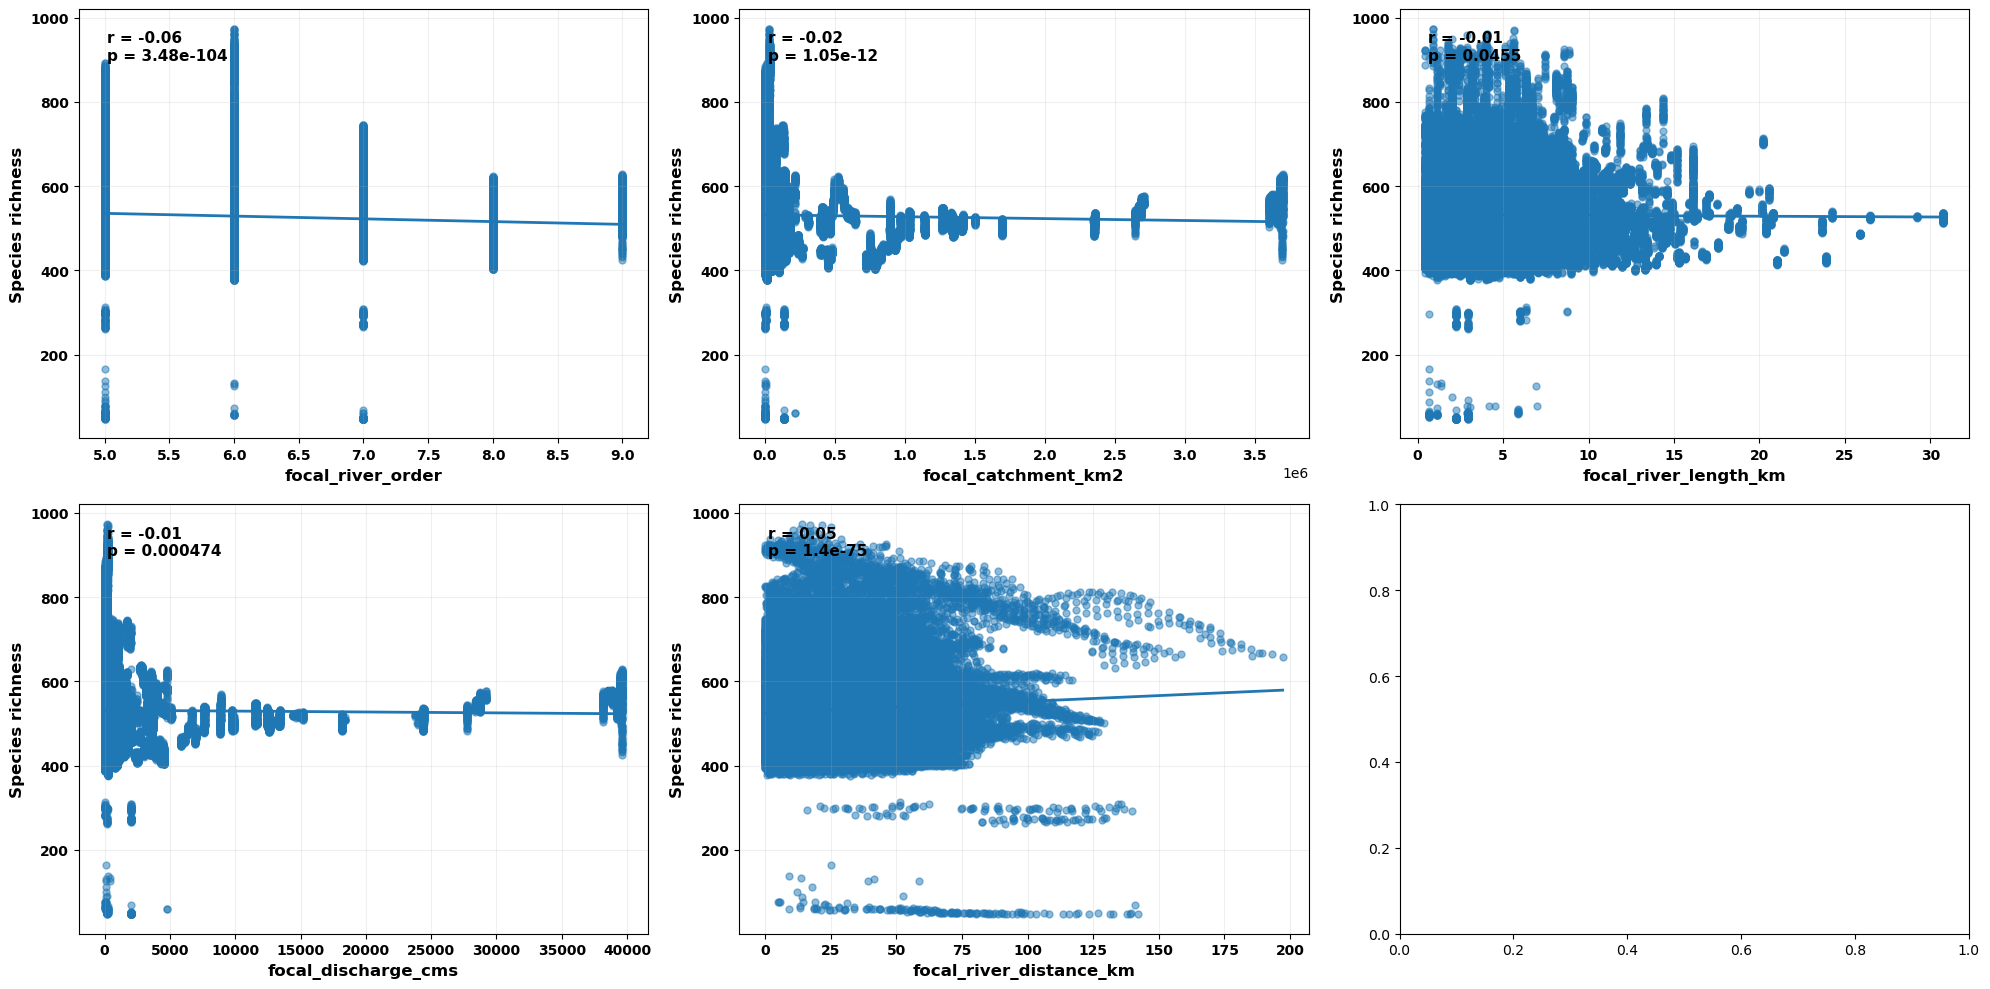

In [41]:
import matplotlib.pyplot as plt
from scipy.stats import pearsonr
import numpy as np

rivers_variables = {
    "ORD_STRA": "focal_river_order",
    "UPLAND_SKM": "focal_catchment_km2",
    "LENGTH_KM": "focal_river_length_km",
    "DIS_AV_CMS": "focal_discharge_cms",
    "distance_km": "focal_river_distance_km"
}

fig, axes = plt.subplots(2,3, figsize=(20,10))
axes = axes.flatten()

for ax, (variable, label) in zip(axes, rivers_variables.items()):
    # Removing missing value
    data = river_selected[["richness", variable]].dropna()
    x = data[variable]
    y = data["richness"]
    # Scatter plot
    ax.scatter(x,y, alpha=0.5, s=25)
    # Regression line
    if len(data)>1:
        slope, intercept = np.polyfit(x,y,1)
        x_line = np.linspace(x.min(), x.max(), 100)
        y_line = slope * x_line + intercept

        ax.plot(x_line, y_line, linewidth=2)

        # Pearson correlation
        r, p = pearsonr(x, y)

        ax.text(0.05,0.95,f"r = {r:.2f}\np = {p:.3g}",transform=ax.transAxes,verticalalignment="top",fontweight="bold",fontsize=11)
    # Bold axis labels
    ax.set_xlabel(
        label,
        fontweight="bold",
        fontsize=12
    )

    ax.set_ylabel(
        "Species richness",
        fontweight="bold",
        fontsize=12
    )

    # Bold tick labels
    ax.tick_params(axis="both", labelsize=10)

    for tick in ax.get_xticklabels():
        tick.set_fontweight("bold")

    for tick in ax.get_yticklabels():
        tick.set_fontweight("bold")

    ax.grid(alpha=0.2)

plt.tight_layout()

# Save as high-resolution PNG
plt.savefig(
    "species_richness_river_relationships.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

OVERALL WEIGHTED ENDEMISM VS RIVERS PROPERTIES

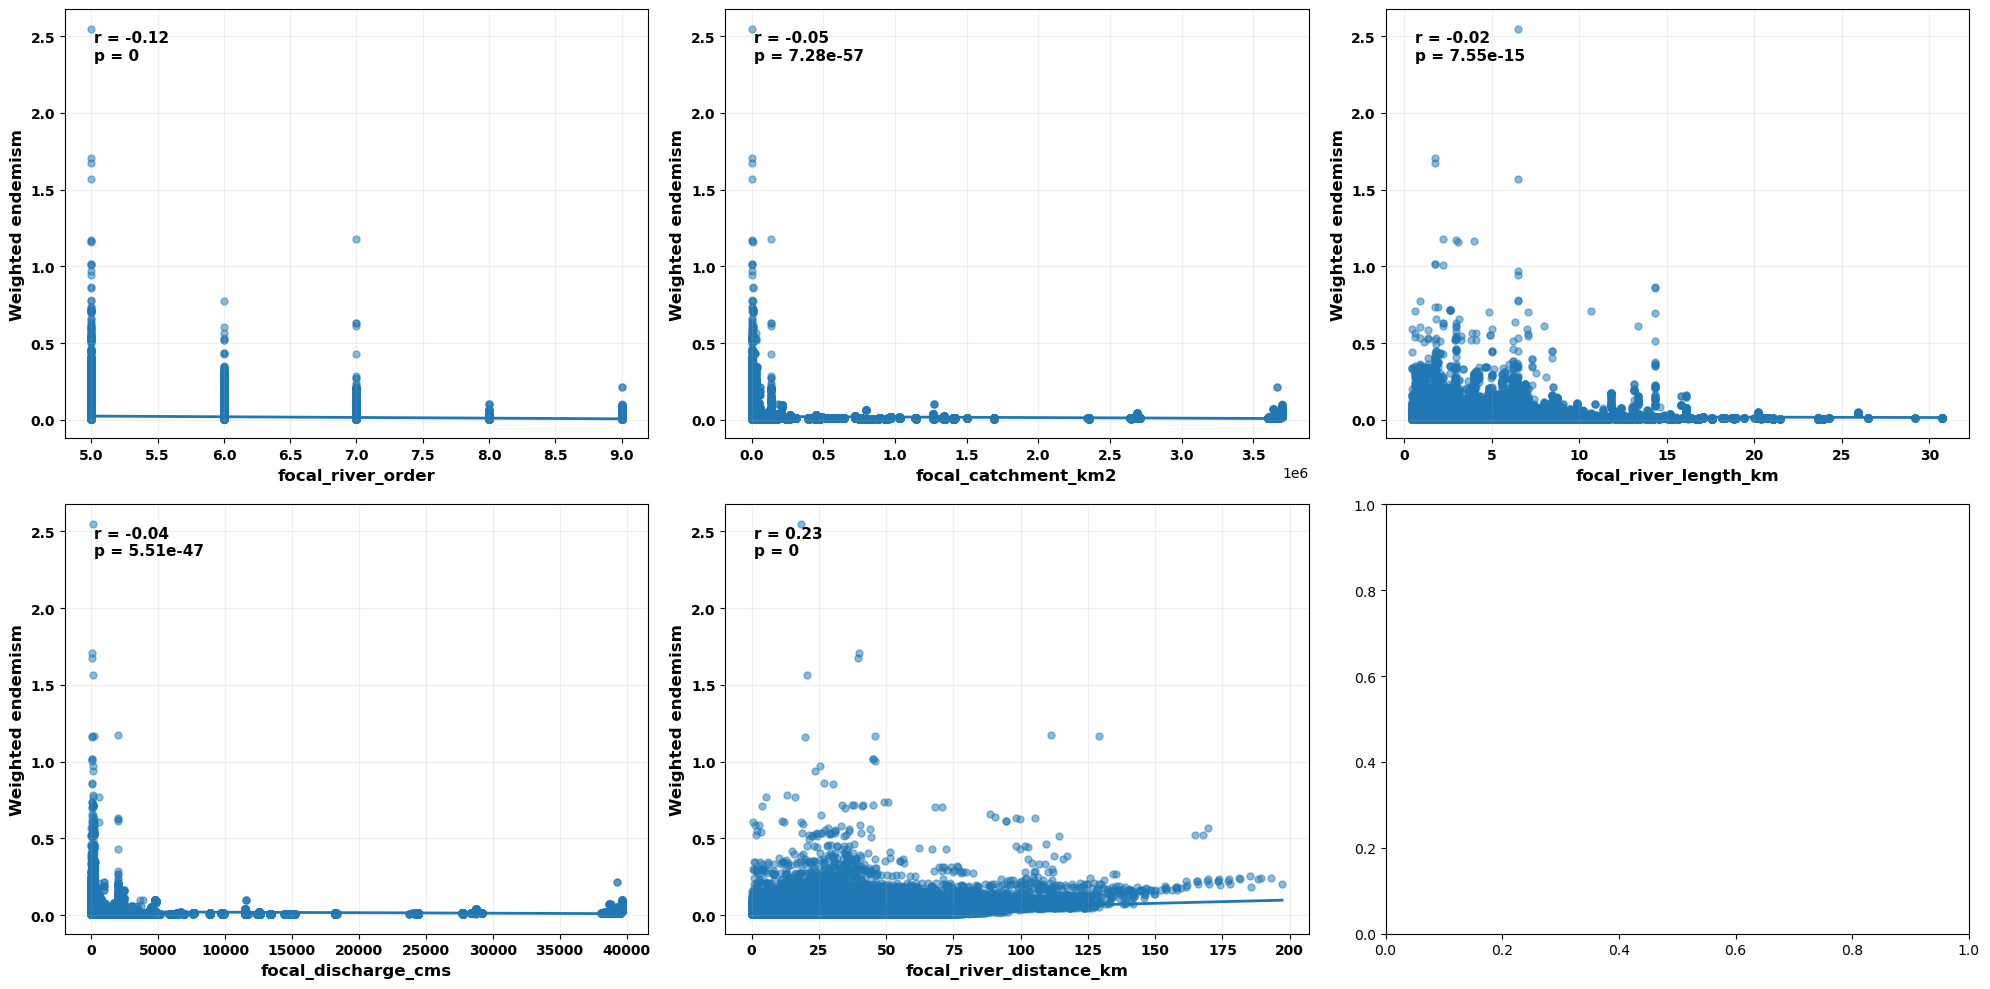

In [42]:
import matplotlib.pyplot as plt
from scipy.stats import pearsonr
import numpy as np

rivers_variables = {
    "ORD_STRA": "focal_river_order",
    "UPLAND_SKM": "focal_catchment_km2",
    "LENGTH_KM": "focal_river_length_km",
    "DIS_AV_CMS": "focal_discharge_cms",
    "distance_km": "focal_river_distance_km"
}

fig, axes = plt.subplots(2,3, figsize=(20,10))
axes = axes.flatten()

for ax, (variable, label) in zip(axes, rivers_variables.items()):
    # Removing missing value
    data = river_selected[["WE", variable]].dropna()
    x = data[variable]
    y = data["WE"]
    # Scatter plot
    ax.scatter(x,y, alpha=0.5, s=25)
    # Regression line
    if len(data)>1:
        slope, intercept = np.polyfit(x,y,1)
        x_line = np.linspace(x.min(), x.max(), 100)
        y_line = slope * x_line + intercept

        ax.plot(x_line, y_line, linewidth=2)

        # Pearson correlation
        r, p = pearsonr(x, y)

        ax.text(0.05,0.95,f"r = {r:.2f}\np = {p:.3g}",transform=ax.transAxes,verticalalignment="top",fontweight="bold",fontsize=11)
    # Bold axis labels
    ax.set_xlabel(
        label,
        fontweight="bold",
        fontsize=12
    )

    ax.set_ylabel(
        "Weighted endemism",
        fontweight="bold",
        fontsize=12
    )

    # Bold tick labels
    ax.tick_params(axis="both", labelsize=10)

    for tick in ax.get_xticklabels():
        tick.set_fontweight("bold")

    for tick in ax.get_yticklabels():
        tick.set_fontweight("bold")

    ax.grid(alpha=0.2)

plt.tight_layout()

# Save as high-resolution PNG
plt.savefig(
    "species_weighted_endemism_river_relationships.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

OVERALL COMMUNITY WEIGHTED ENDEMISM VS RIVERS PROPERTIES

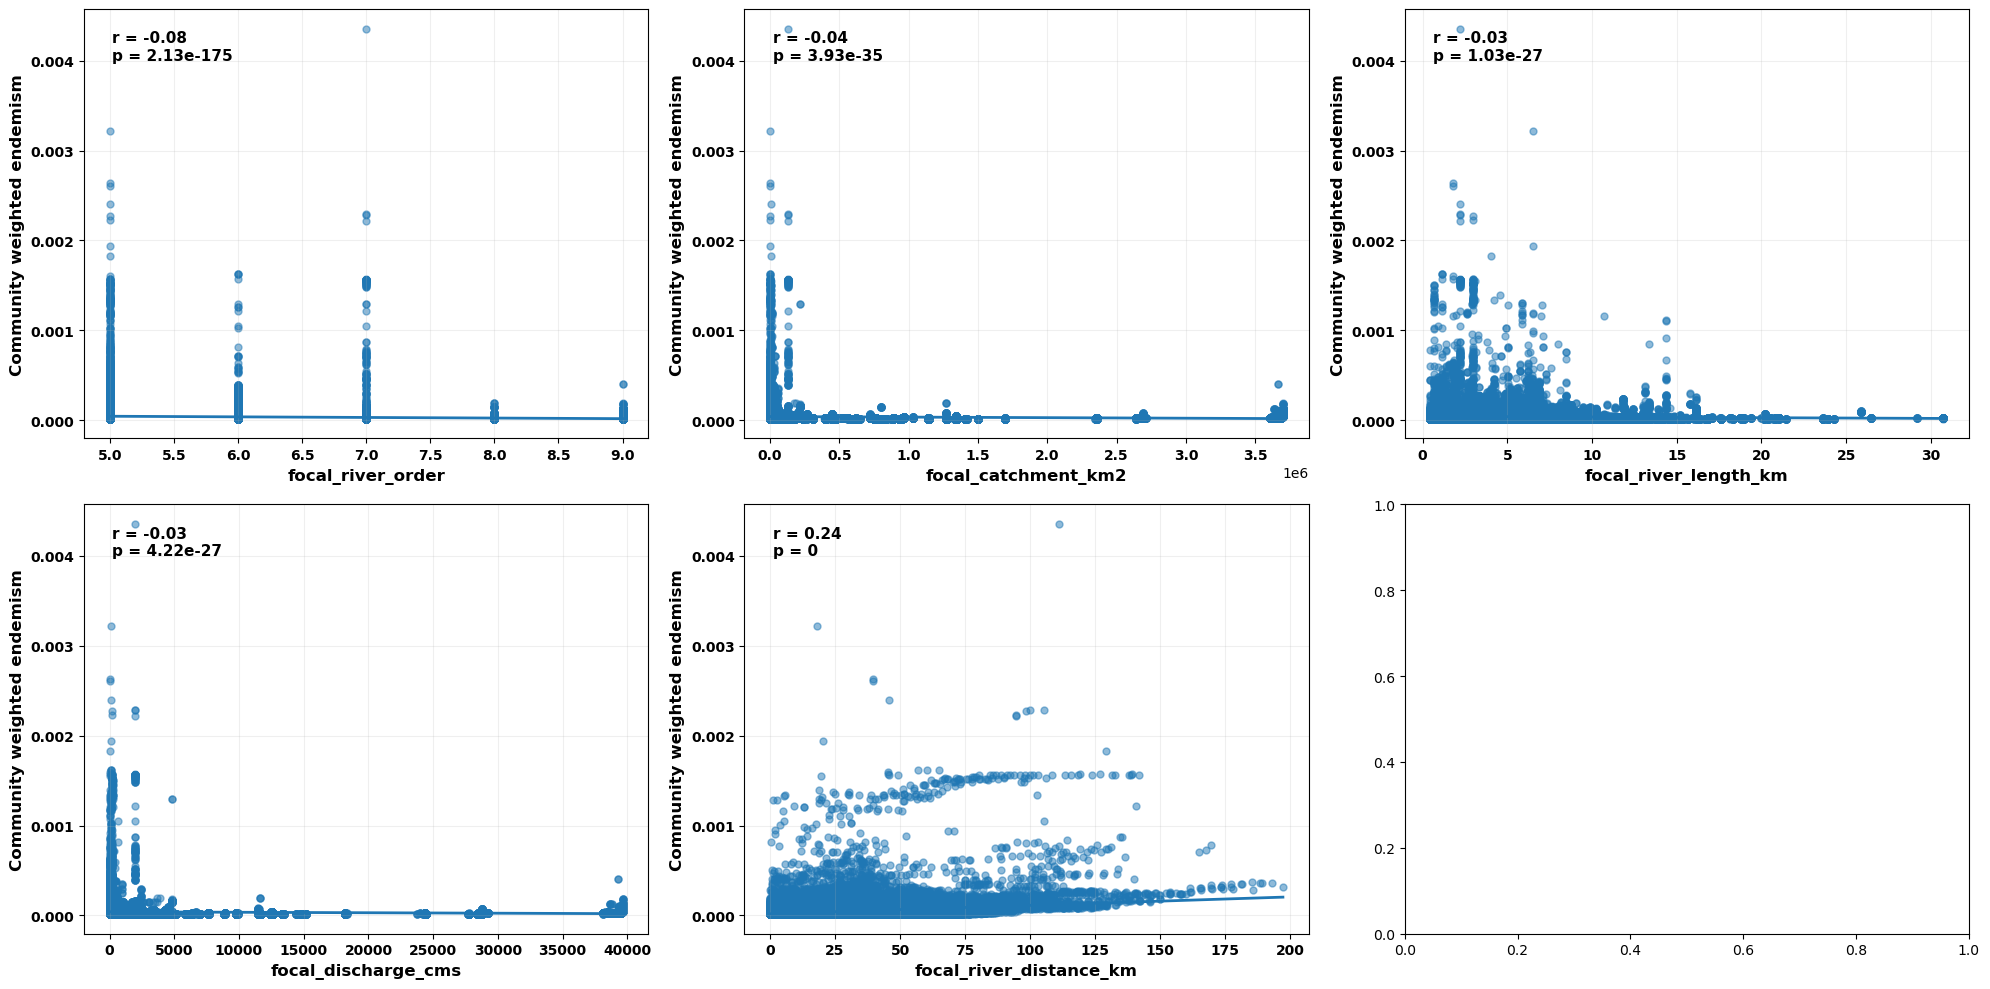

In [43]:
import matplotlib.pyplot as plt
from scipy.stats import pearsonr
import numpy as np

rivers_variables = {
    "ORD_STRA": "focal_river_order",
    "UPLAND_SKM": "focal_catchment_km2",
    "LENGTH_KM": "focal_river_length_km",
    "DIS_AV_CMS": "focal_discharge_cms",
    "distance_km": "focal_river_distance_km"
}

fig, axes = plt.subplots(2,3, figsize=(20,10))
axes = axes.flatten()

for ax, (variable, label) in zip(axes, rivers_variables.items()):
    # Removing missing value
    data = river_selected[["CWE", variable]].dropna()
    x = data[variable]
    y = data["CWE"]
    # Scatter plot
    ax.scatter(x,y, alpha=0.5, s=25)
    # Regression line
    if len(data)>1:
        slope, intercept = np.polyfit(x,y,1)
        x_line = np.linspace(x.min(), x.max(), 100)
        y_line = slope * x_line + intercept

        ax.plot(x_line, y_line, linewidth=2)

        # Pearson correlation
        r, p = pearsonr(x, y)

        ax.text(0.05,0.95,f"r = {r:.2f}\np = {p:.3g}",transform=ax.transAxes,verticalalignment="top",fontweight="bold",fontsize=11)
    # Bold axis labels
    ax.set_xlabel(
        label,
        fontweight="bold",
        fontsize=12
    )

    ax.set_ylabel(
        "Community weighted endemism",
        fontweight="bold",
        fontsize=12
    )

    # Bold tick labels
    ax.tick_params(axis="both", labelsize=10)

    for tick in ax.get_xticklabels():
        tick.set_fontweight("bold")

    for tick in ax.get_yticklabels():
        tick.set_fontweight("bold")

    ax.grid(alpha=0.2)

plt.tight_layout()

# Save as high-resolution PNG
plt.savefig(
    "species_community_weighted_endemism_river_relationships.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

TAXONOMIC (bird,amphibian,reptile,mammal) RICHNESS VS RIVERS PROPERTIES

In [44]:
birds = gpd.read_file("data/grid_bird_biodiversity.gpkg")
mammals = gpd.read_file("data/grid_mammal_biodiversity.gpkg")
amphibians = gpd.read_file("data/grid_amphibian_biodiversity.gpkg")
reptiles = gpd.read_file("data/grid_reptile_biodiversity.gpkg")

In [46]:
birds = birds.merge(
    river_selected[['grid','distance_km','river_direction','ORD_STRA','UPLAND_SKM','LENGTH_KM','DIS_AV_CMS']],on="grid",how="left")
mammals = mammals.merge(
    river_selected[['grid','distance_km','river_direction','ORD_STRA','UPLAND_SKM','LENGTH_KM','DIS_AV_CMS']],on="grid",how="left")
amphibians = amphibians.merge(
    river_selected[['grid','distance_km','river_direction','ORD_STRA','UPLAND_SKM','LENGTH_KM','DIS_AV_CMS']],on="grid",how="left")
reptiles=reptiles.merge(
    river_selected[['grid','distance_km','river_direction','ORD_STRA','UPLAND_SKM','LENGTH_KM','DIS_AV_CMS']],on="grid",how="left")

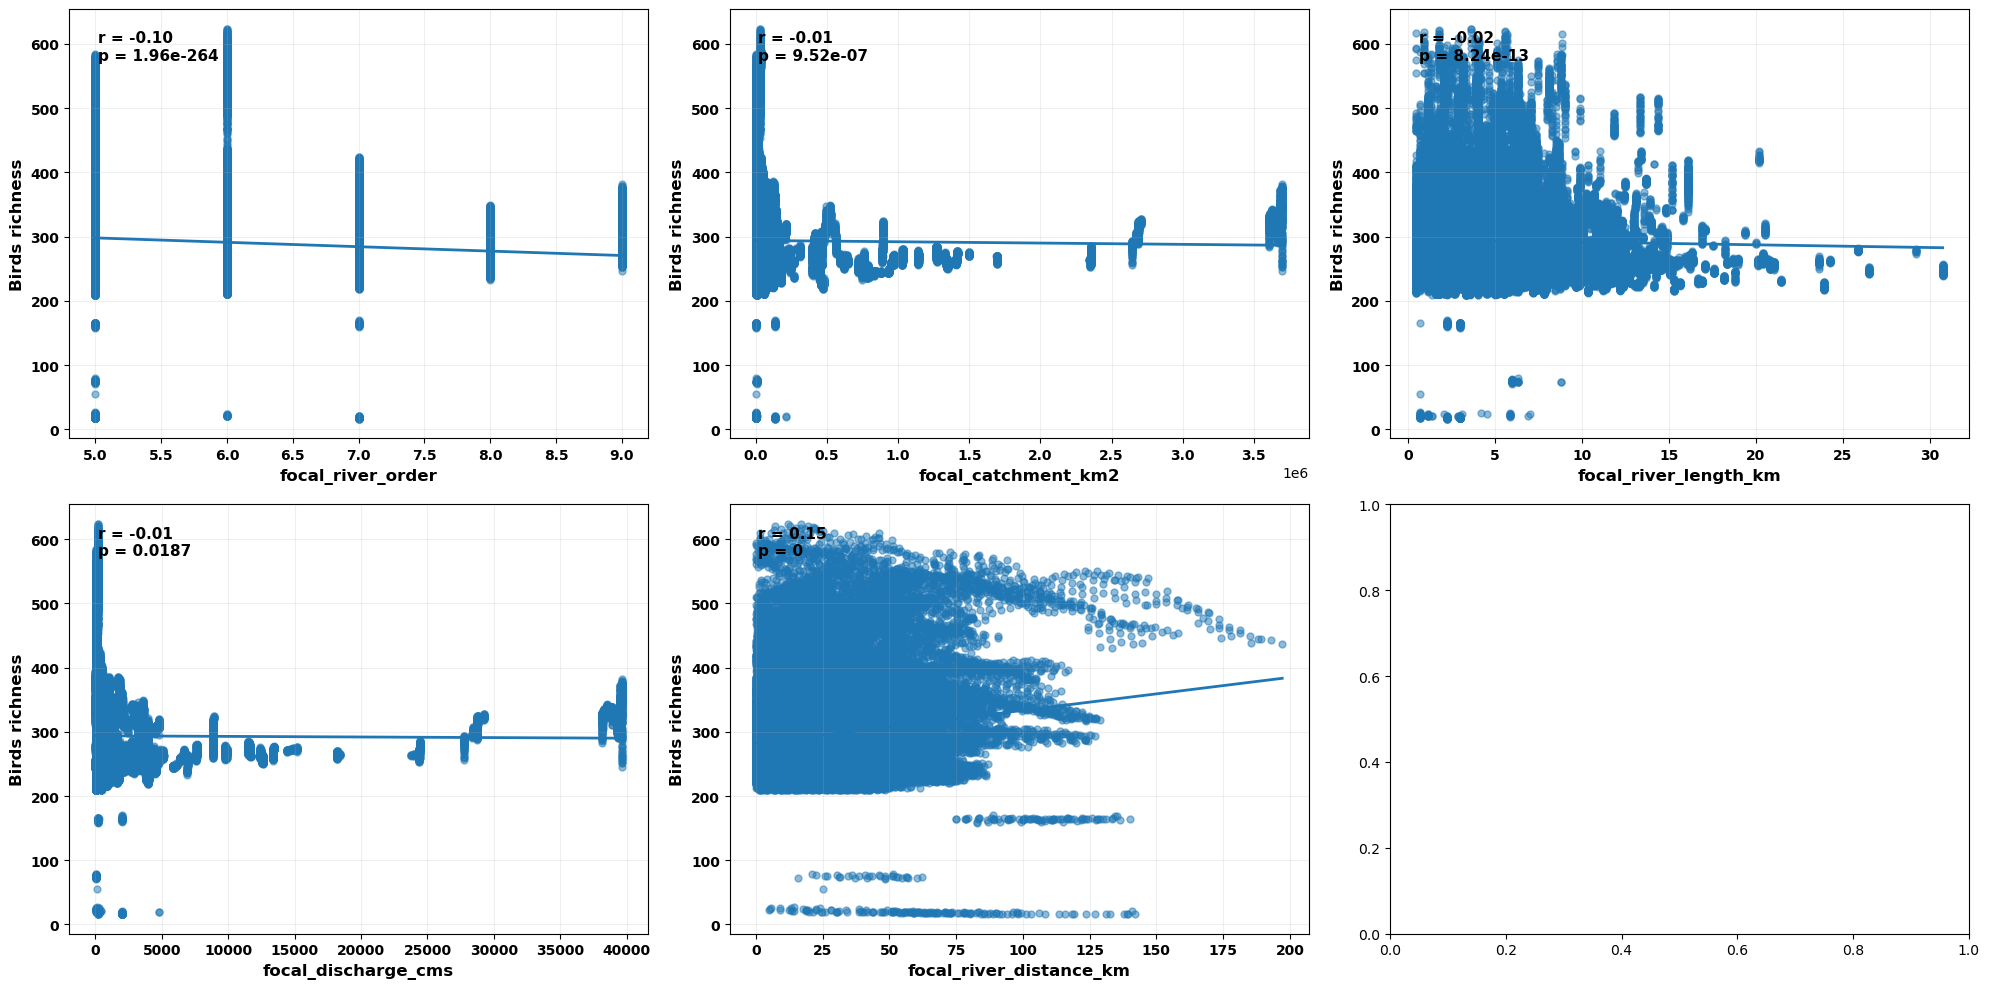

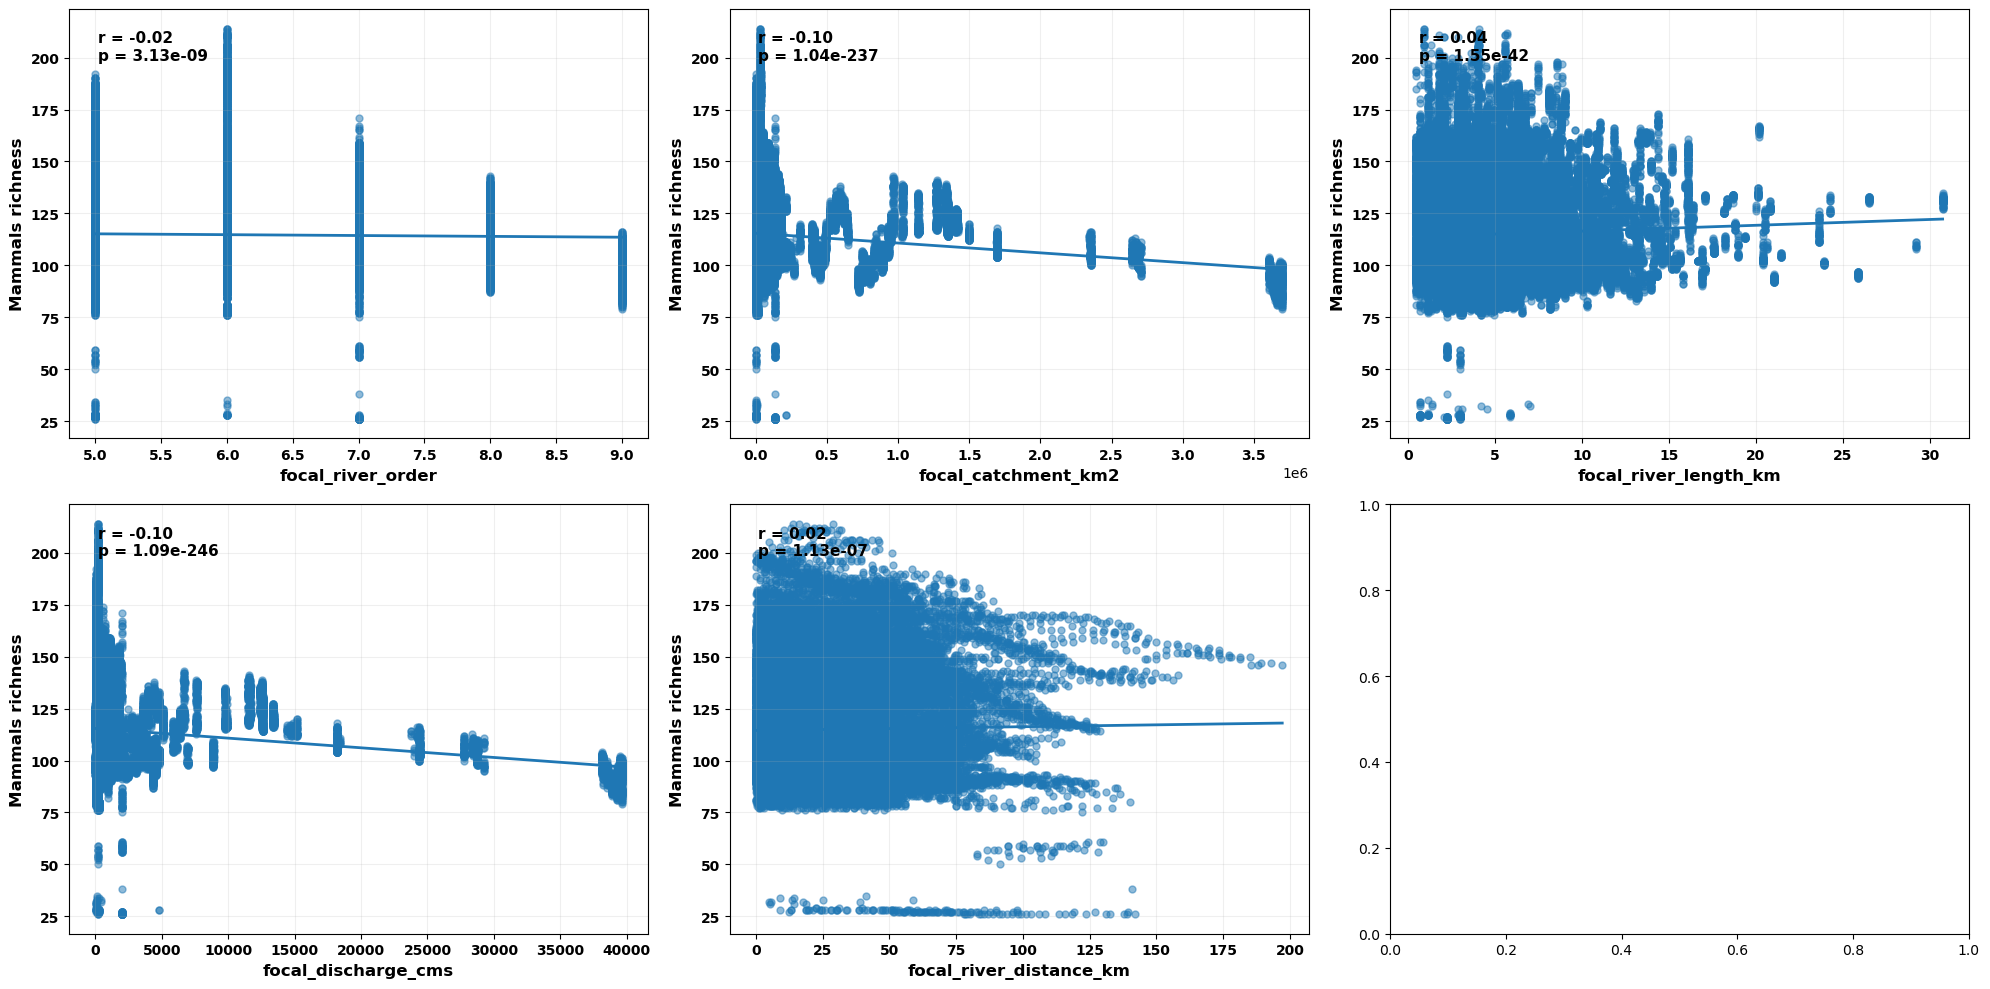

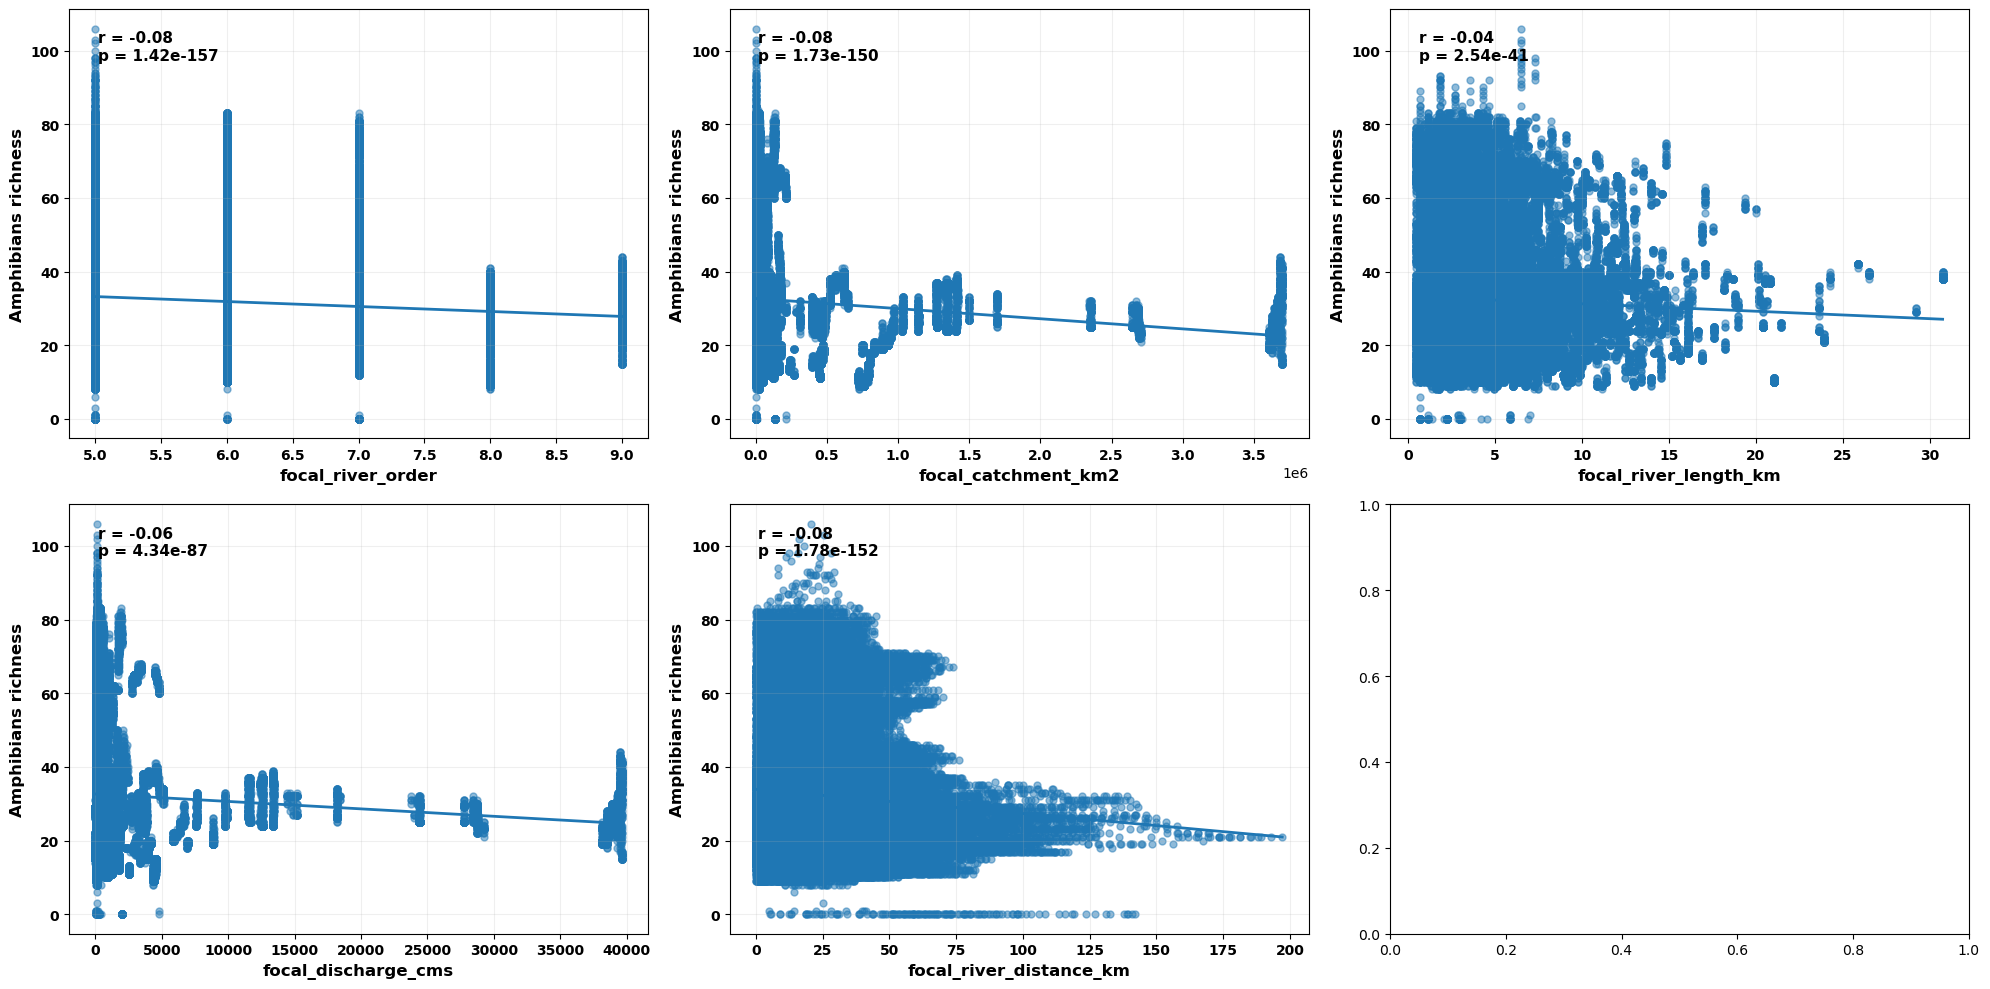

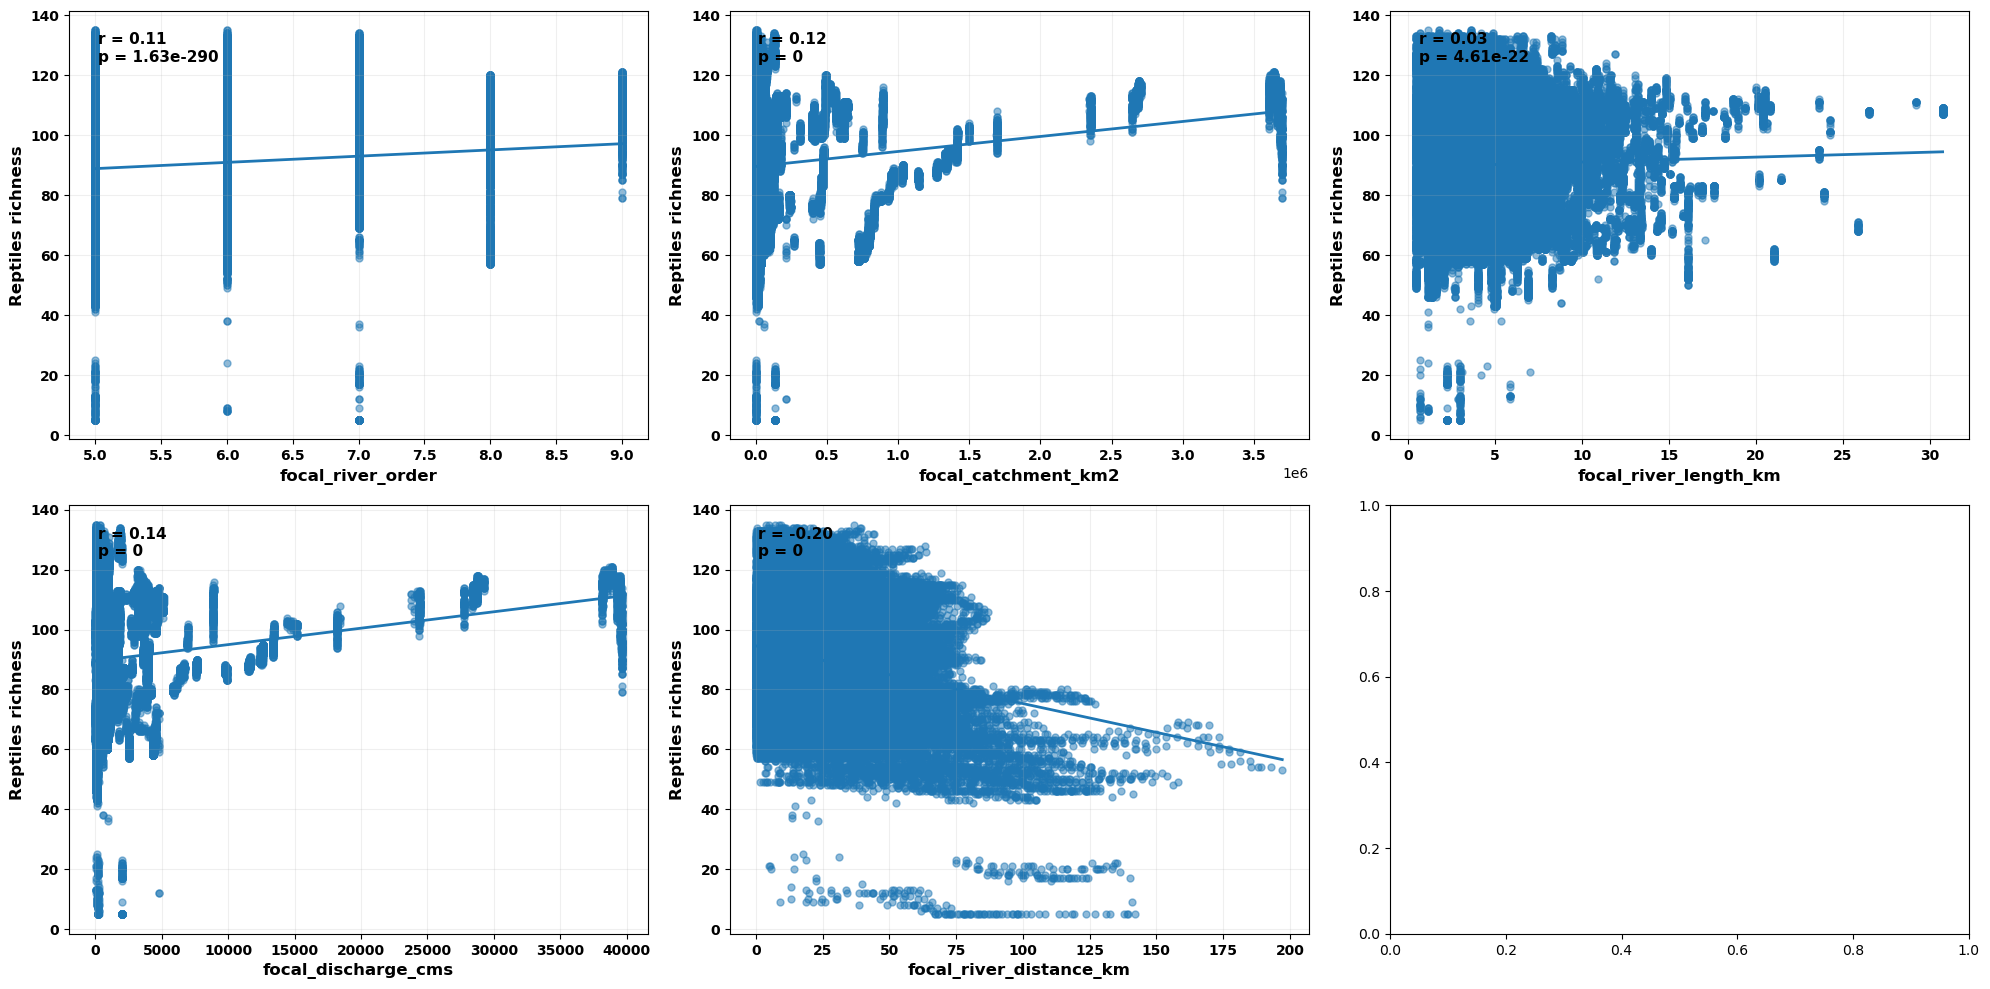

In [48]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import pearsonr

rivers_variables = {
    "ORD_STRA": "focal_river_order",
    "UPLAND_SKM": "focal_catchment_km2",
    "LENGTH_KM": "focal_river_length_km",
    "DIS_AV_CMS": "focal_discharge_cms",
    "distance_km": "focal_river_distance_km"
}

taxon_dataset=[birds, mammals, amphibians, reptiles]
label_t = ["Birds", "Mammals", "Amphibians", "Reptiles"]

for index, taxon in enumerate(taxon_dataset):
    fig, axes = plt.subplots(2,3, figsize=(20,10))
    axes = axes.flatten()
    
    for ax, (variable, label) in zip(axes, rivers_variables.items()):
        # Removing missing value
        data = taxon[["richness", variable]].dropna()
        x = data[variable]
        y = data["richness"]
        
        # Scatter plot
        ax.scatter(x,y, alpha=0.5, s=25)
        # Regression line
        if len(data)>1:
            slope, intercept = np.polyfit(x,y,1)
            x_line = np.linspace(x.min(), x.max(), 100)
            y_line = slope * x_line + intercept
            ax.plot(x_line, y_line, linewidth=2)
            # Pearson correlation
            r, p = pearsonr(x, y)
            ax.text(0.05,0.95,f"r = {r:.2f}\np = {p:.3g}",transform=ax.transAxes,verticalalignment="top",fontweight="bold",fontsize=11)
            
        # Bold axis labels
        ax.set_xlabel(label,fontweight="bold",fontsize=12)
        ax.set_ylabel(label_t[index]+" richness",fontweight="bold",fontsize=12)

        # Bold tick labels
        ax.tick_params(axis="both", labelsize=10)

        for tick in ax.get_xticklabels():
            tick.set_fontweight("bold")

        for tick in ax.get_yticklabels():
            tick.set_fontweight("bold")

        ax.grid(alpha=0.2)

    plt.tight_layout()
    # Save as high-resolution PNG
    plt.savefig(label_t[index]+"_richness_river_relationships.png",dpi=300,bbox_inches="tight")
    plt.show()

TAXONOMIC (bird,amphibian,reptile,mammal) WEIGHTED ENDEMISM VS RIVERS PROPERTIES

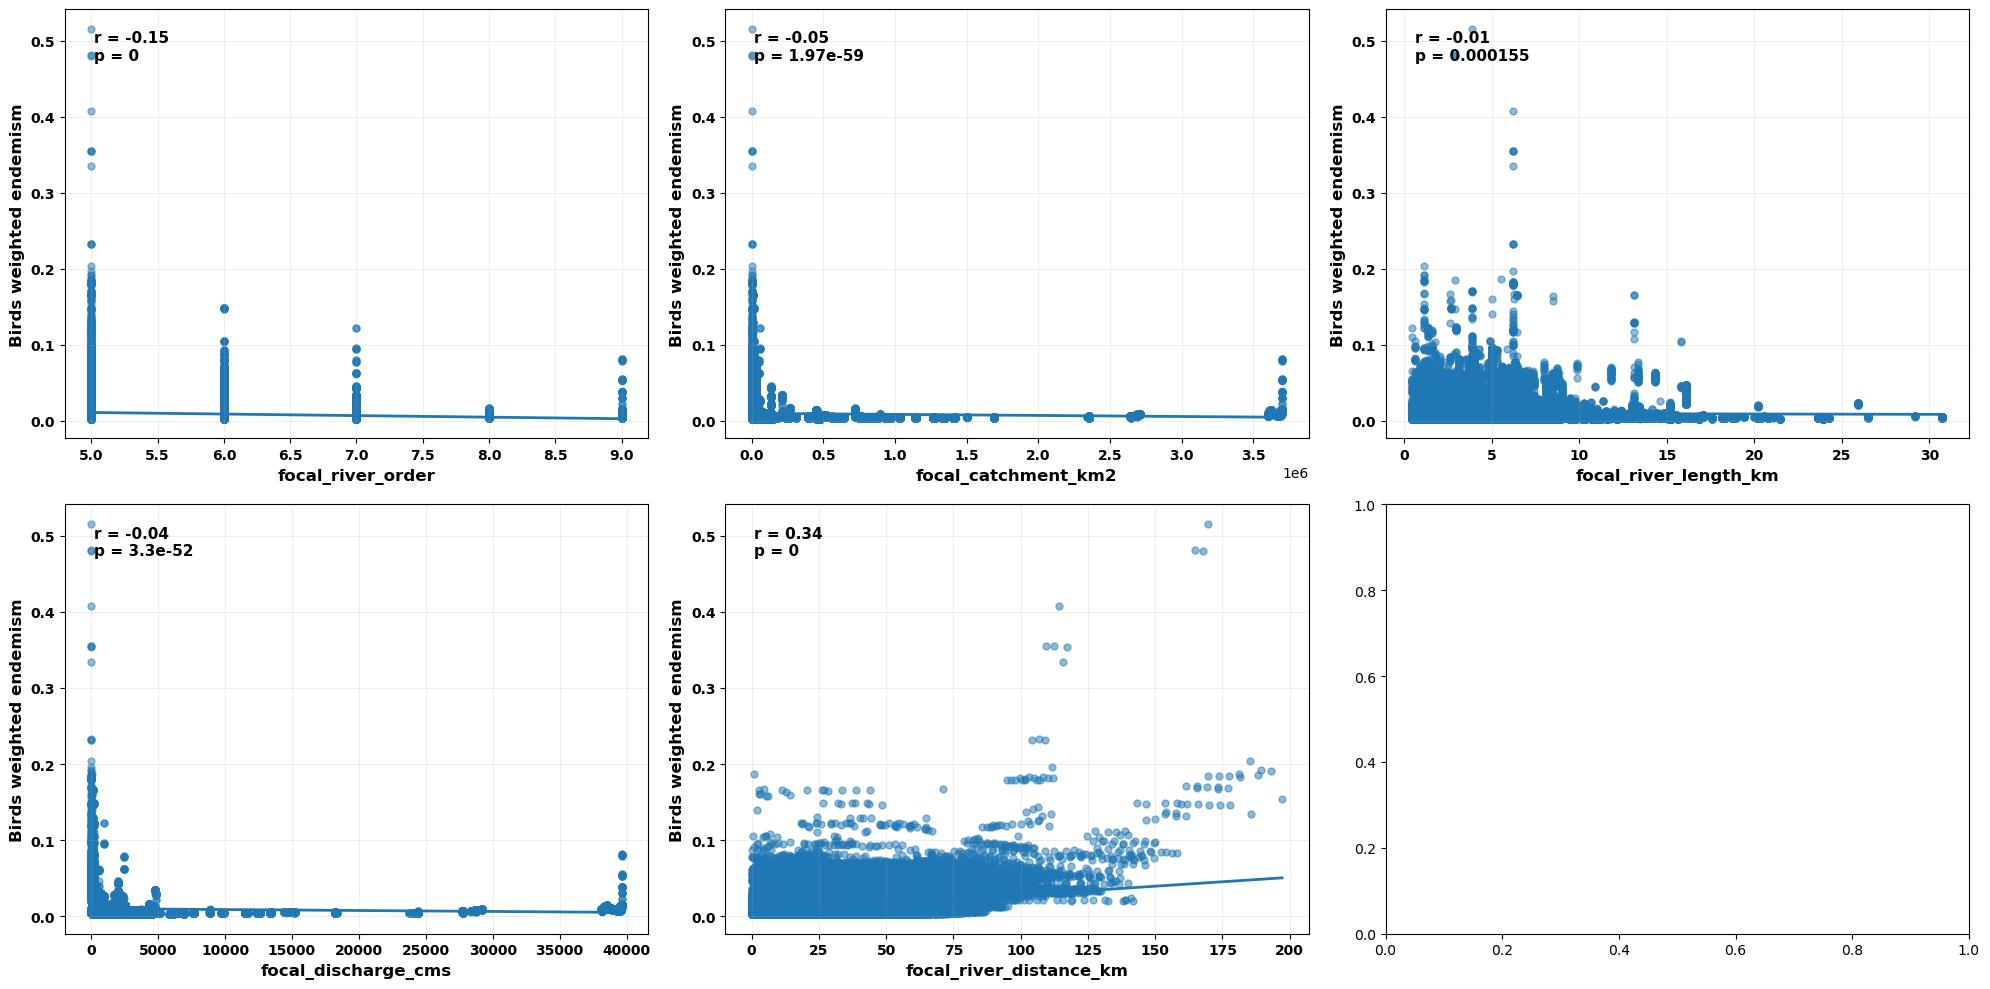

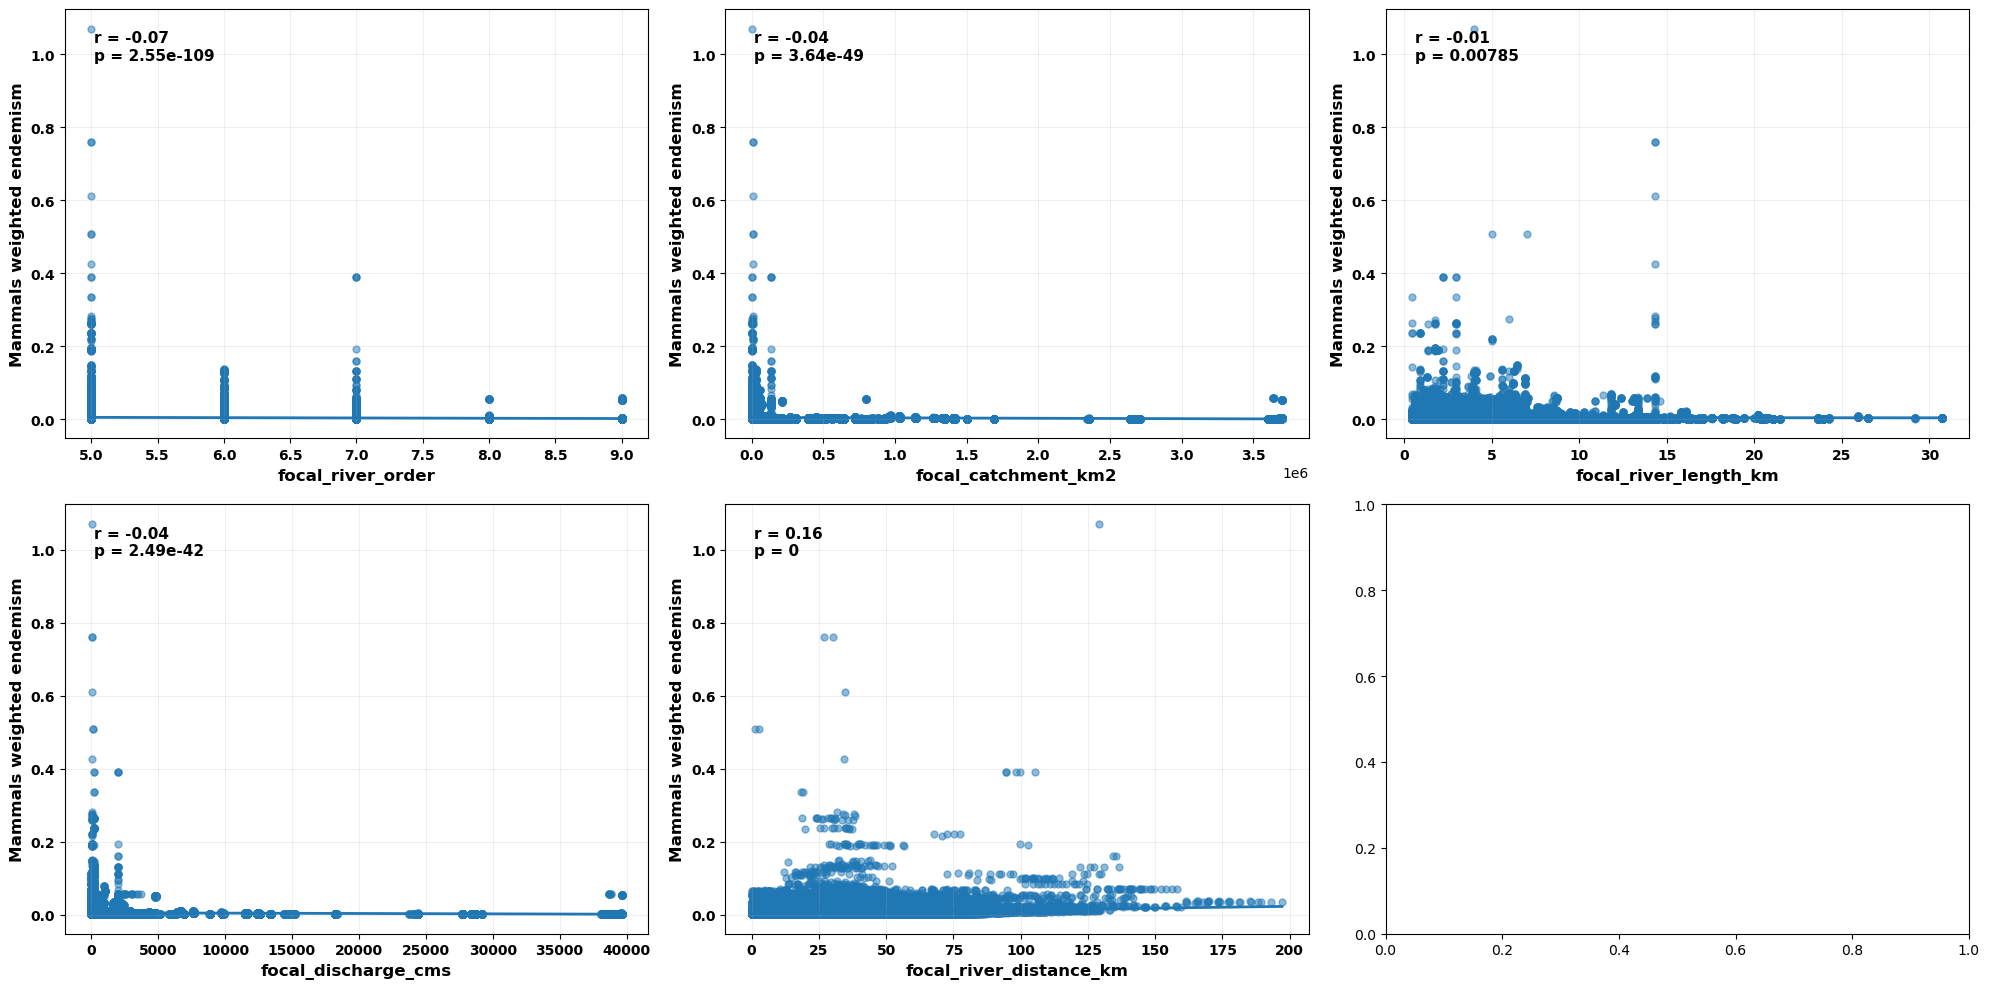

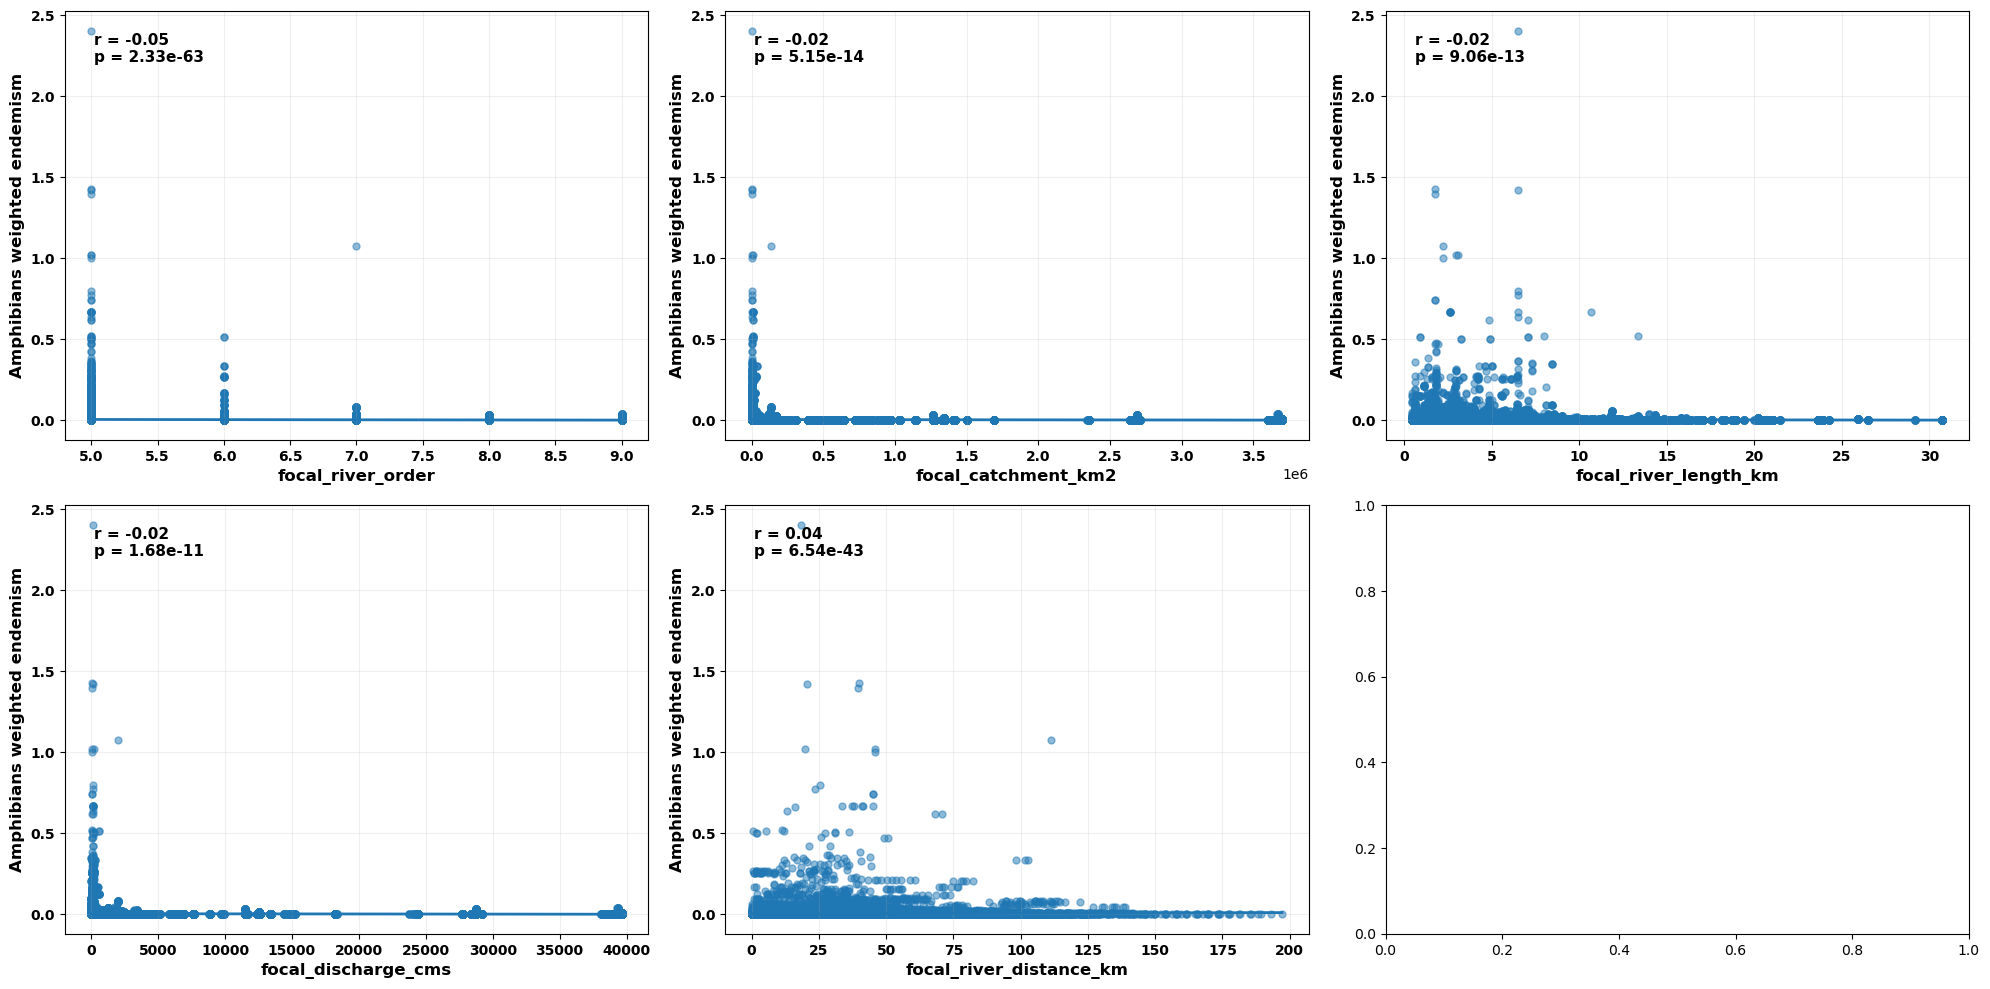

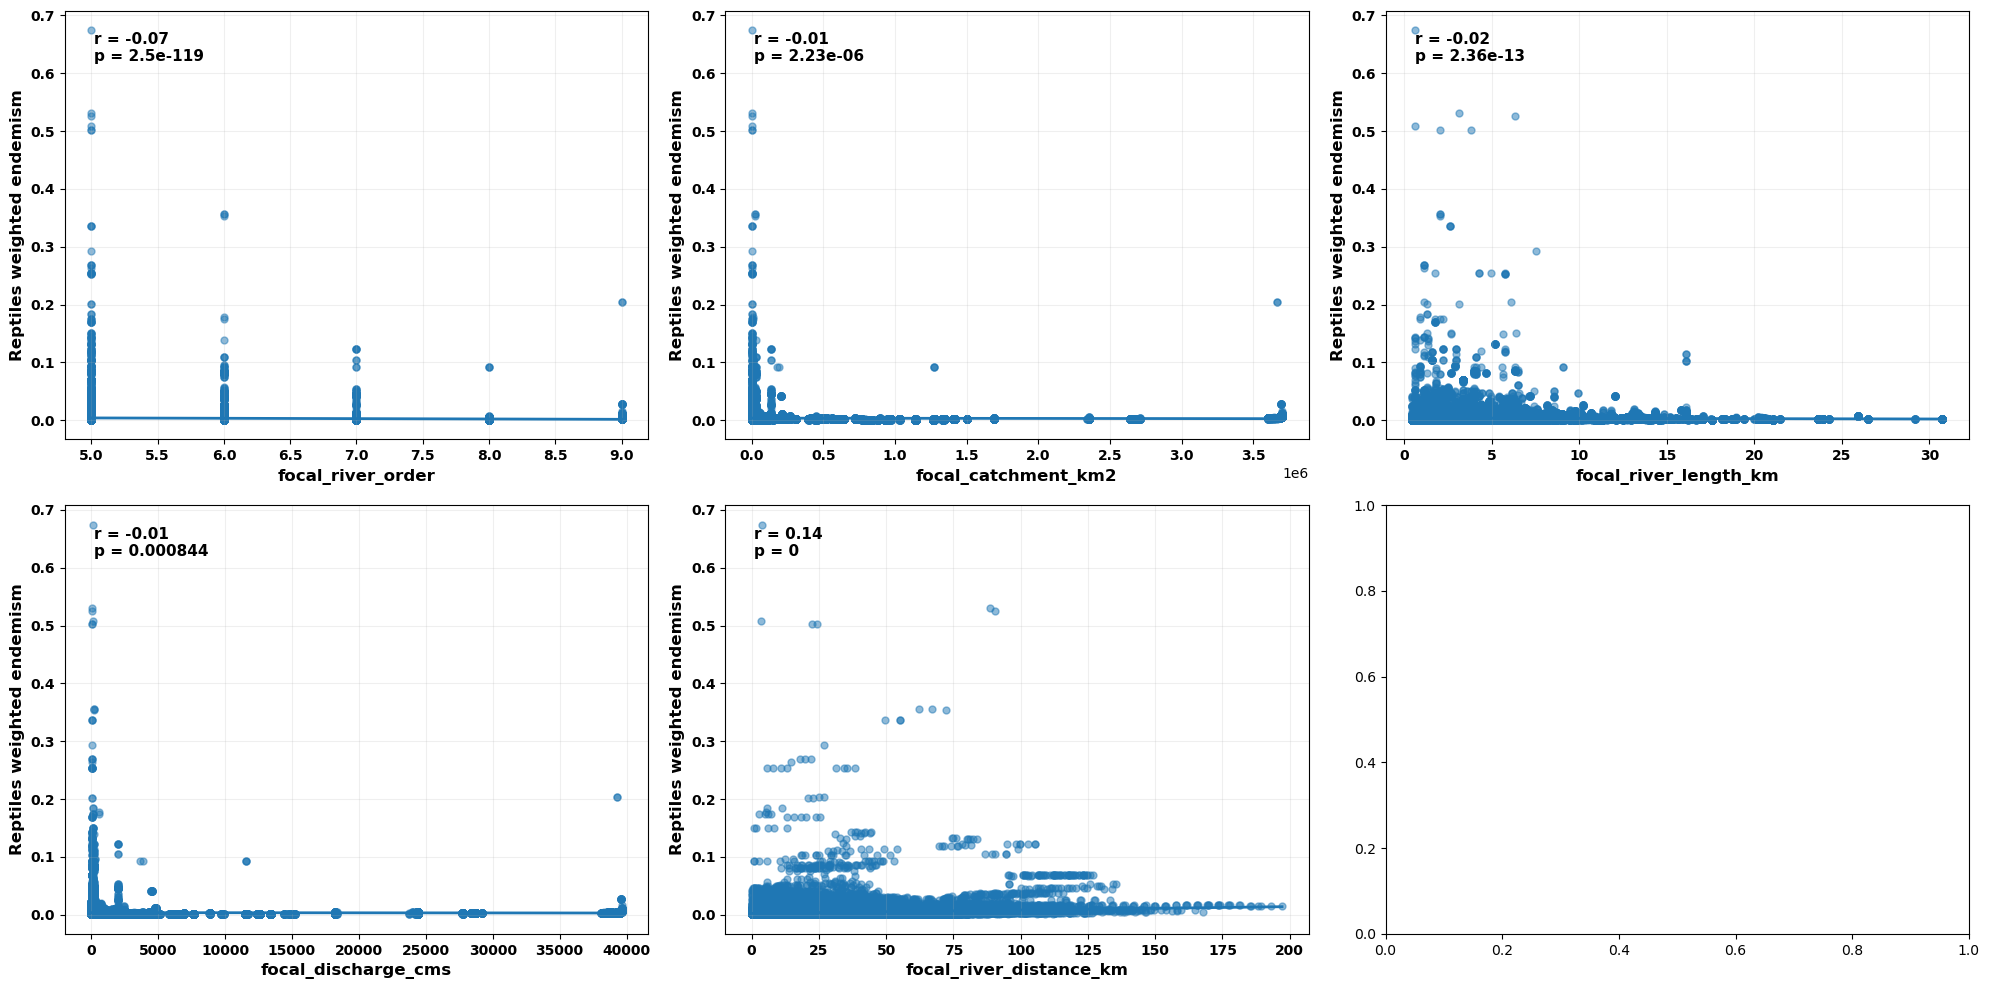

In [49]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import pearsonr

rivers_variables = {
    "ORD_STRA": "focal_river_order",
    "UPLAND_SKM": "focal_catchment_km2",
    "LENGTH_KM": "focal_river_length_km",
    "DIS_AV_CMS": "focal_discharge_cms",
    "distance_km": "focal_river_distance_km"
}

taxon_dataset=[birds, mammals, amphibians, reptiles]
label_t = ["Birds", "Mammals", "Amphibians", "Reptiles"]

for index, taxon in enumerate(taxon_dataset):
    fig, axes = plt.subplots(2,3, figsize=(20,10))
    axes = axes.flatten()
    
    for ax, (variable, label) in zip(axes, rivers_variables.items()):
        # Removing missing value
        data = taxon[["WE", variable]].dropna()
        x = data[variable]
        y = data["WE"]
        
        # Scatter plot
        ax.scatter(x,y, alpha=0.5, s=25)
        # Regression line
        if len(data)>1:
            slope, intercept = np.polyfit(x,y,1)
            x_line = np.linspace(x.min(), x.max(), 100)
            y_line = slope * x_line + intercept
            ax.plot(x_line, y_line, linewidth=2)
            # Pearson correlation
            r, p = pearsonr(x, y)
            ax.text(0.05,0.95,f"r = {r:.2f}\np = {p:.3g}",transform=ax.transAxes,verticalalignment="top",fontweight="bold",fontsize=11)
            
        # Bold axis labels
        ax.set_xlabel(label,fontweight="bold",fontsize=12)
        ax.set_ylabel(label_t[index]+" weighted endemism",fontweight="bold",fontsize=12)

        # Bold tick labels
        ax.tick_params(axis="both", labelsize=10)

        for tick in ax.get_xticklabels():
            tick.set_fontweight("bold")

        for tick in ax.get_yticklabels():
            tick.set_fontweight("bold")

        ax.grid(alpha=0.2)

    plt.tight_layout()
    # Save as high-resolution PNG
    plt.savefig(label_t[index]+"_weighted_endemism_river_relationships.png",dpi=300,bbox_inches="tight")
    plt.show()

TAXONOMIC (bird,amphibian,reptile,mammal) COMMUNITY WEIGHTED ENDEMISM VS RIVERS PROPERTIES

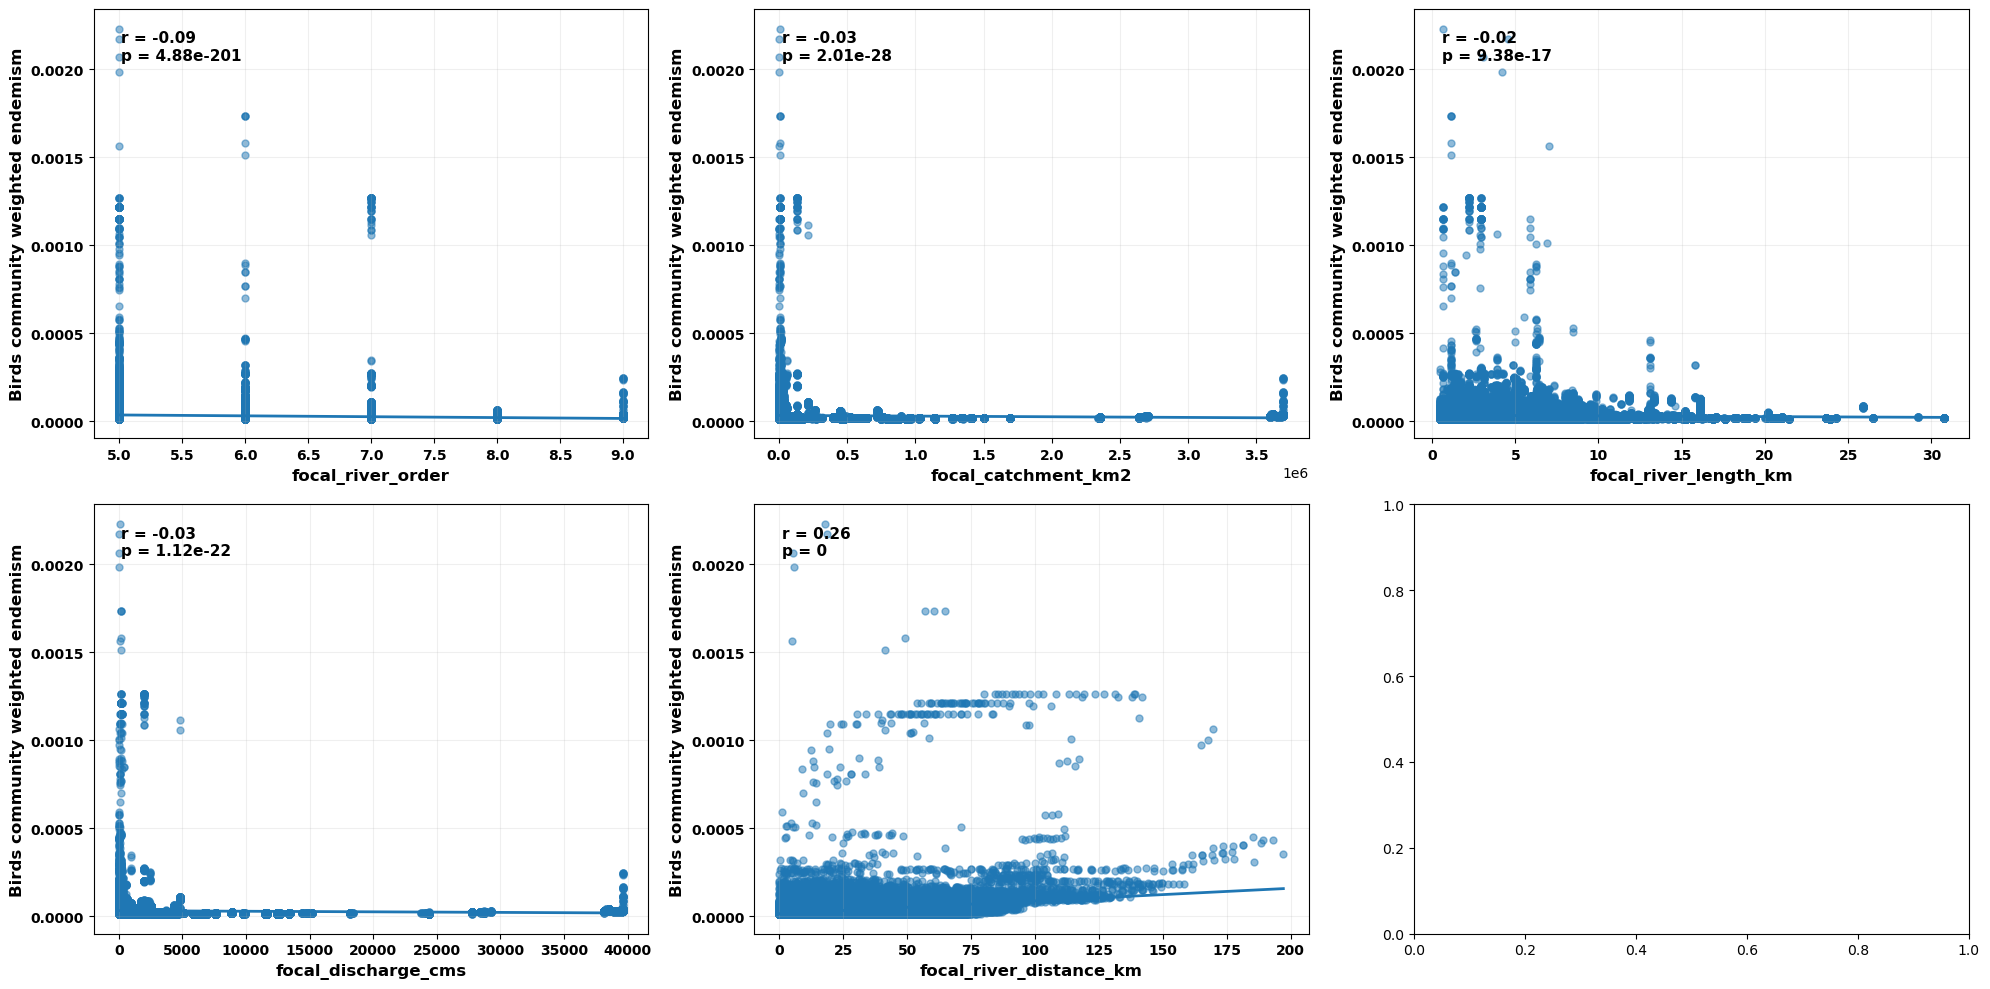

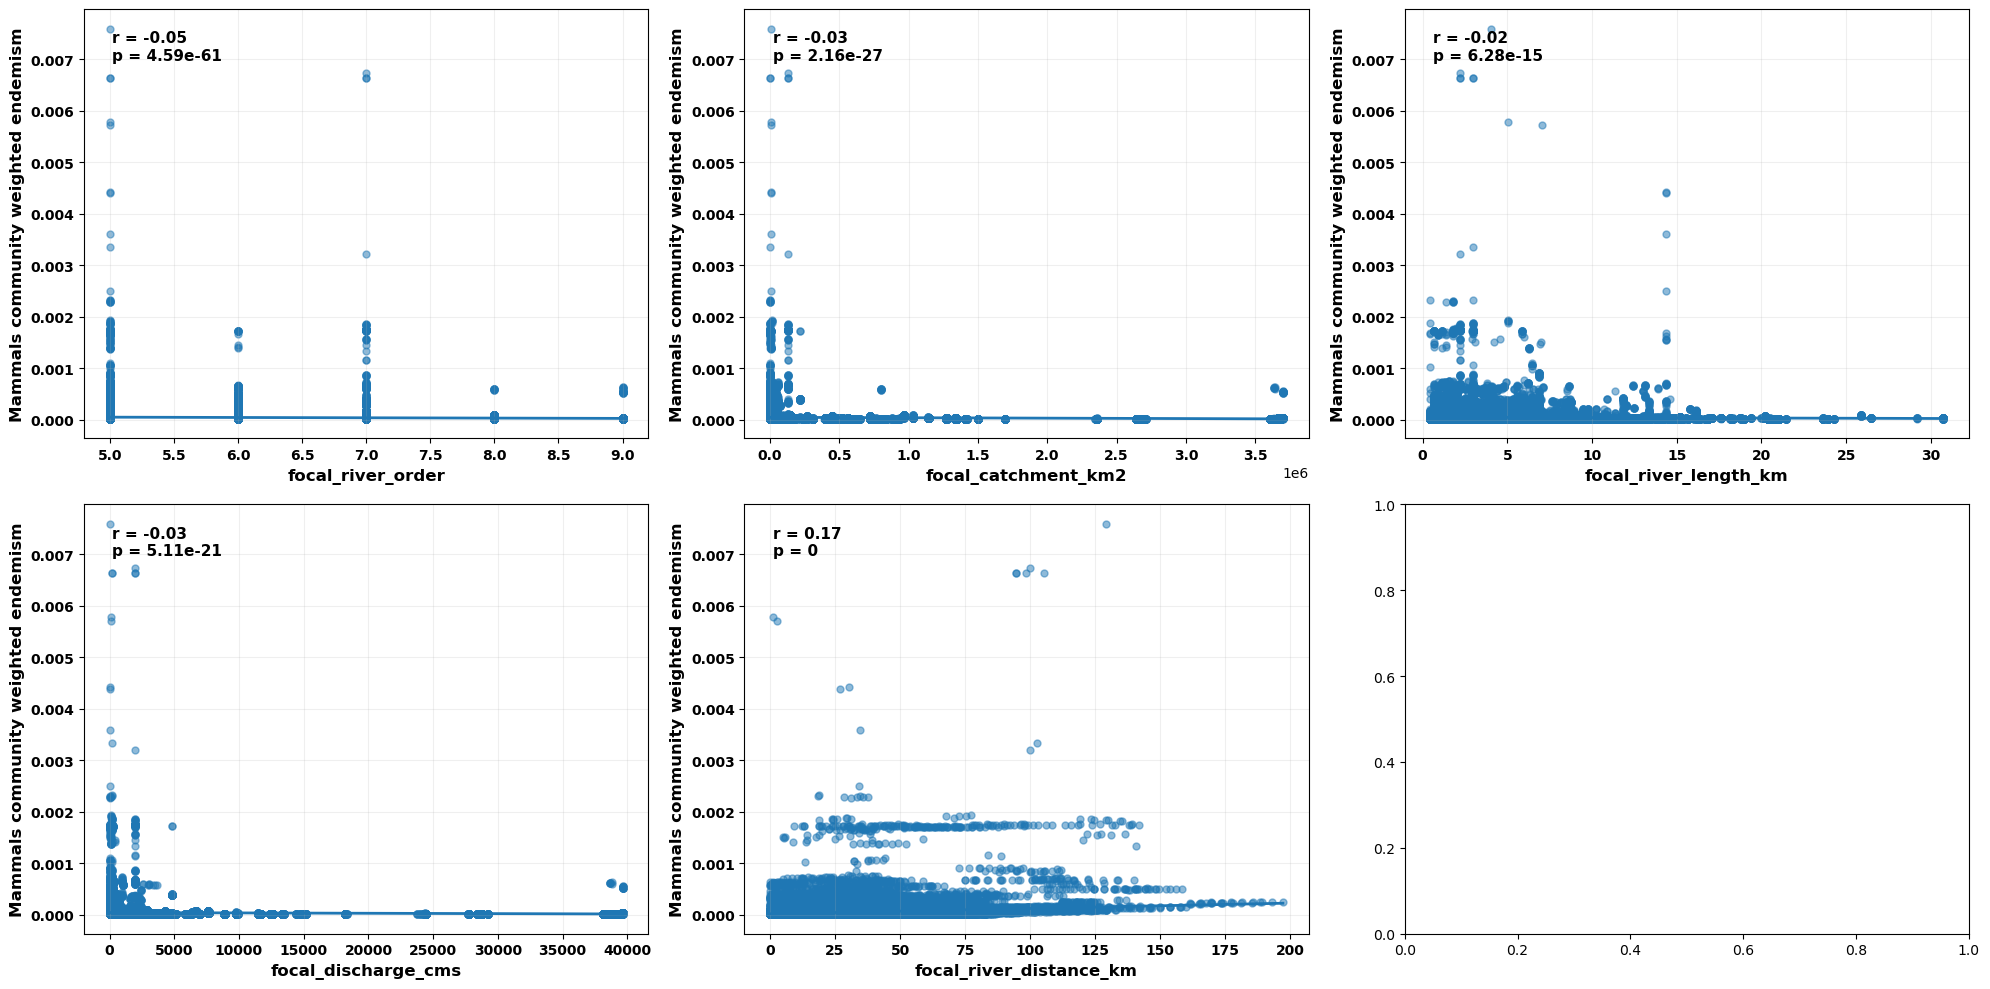

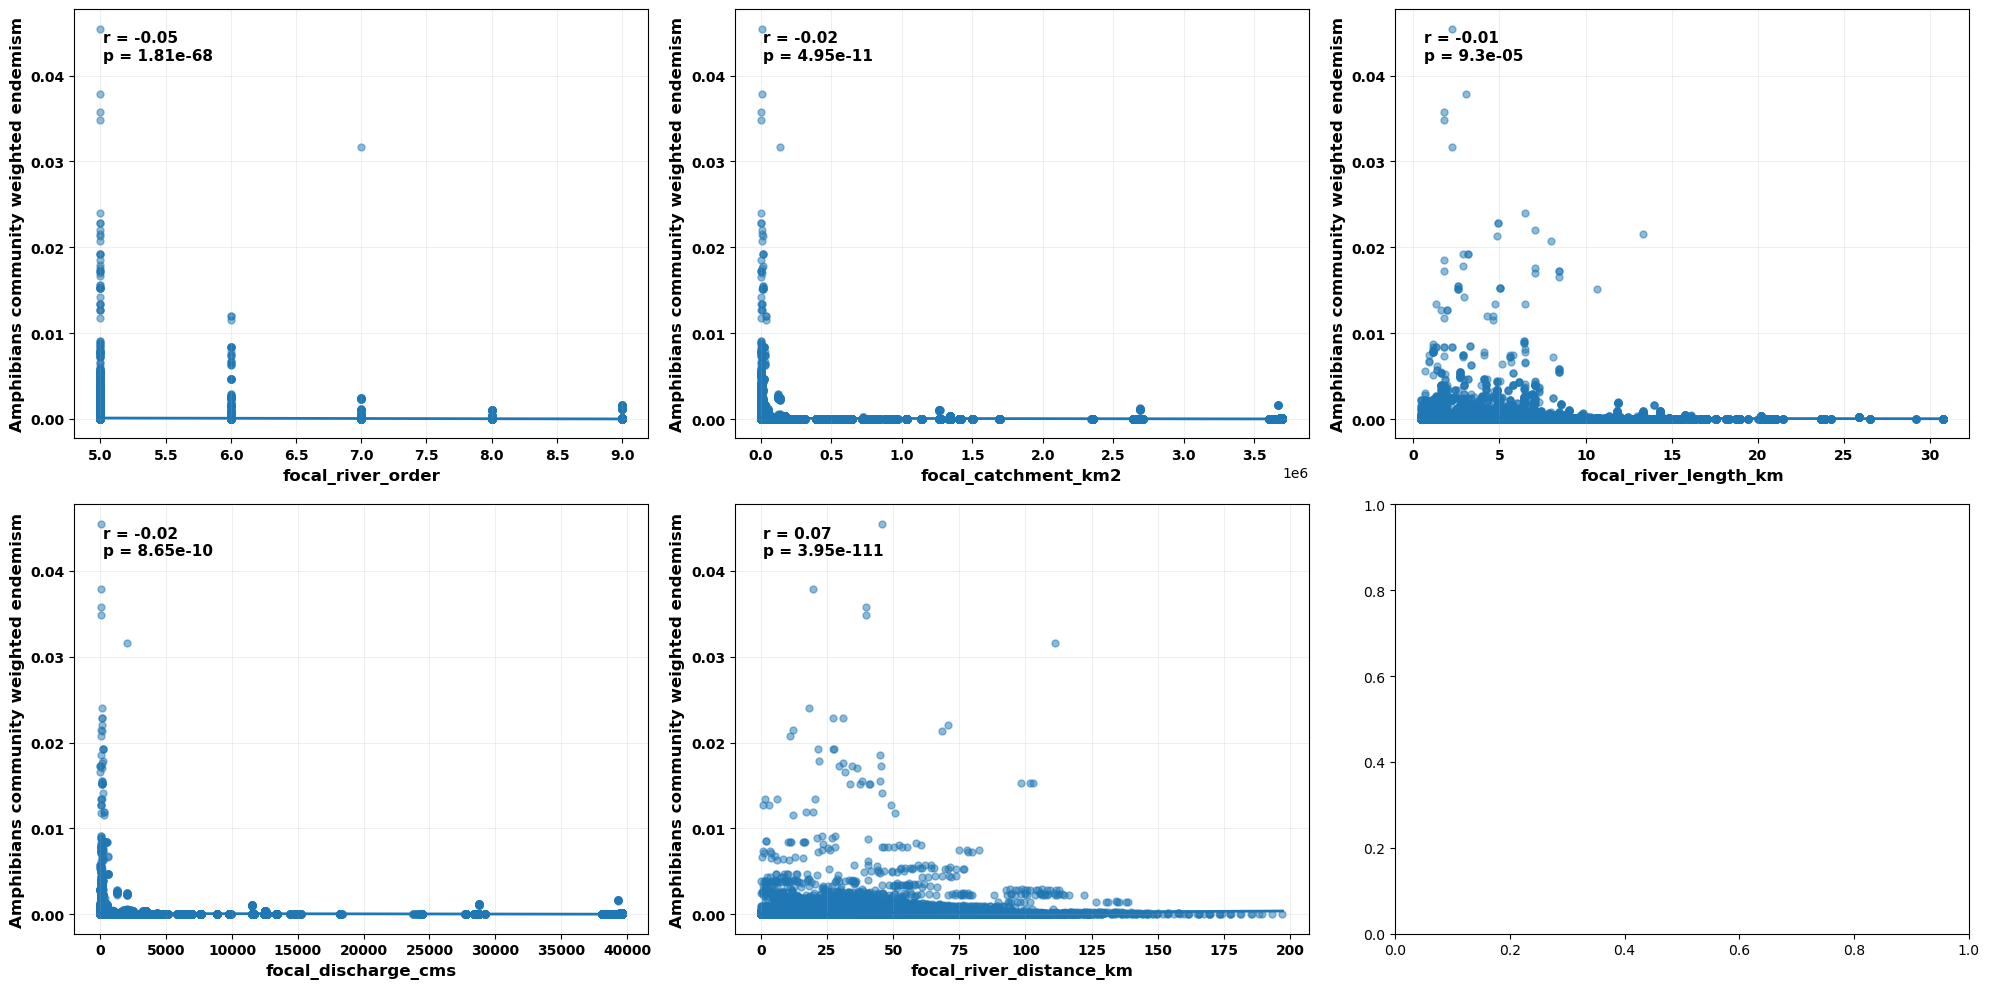

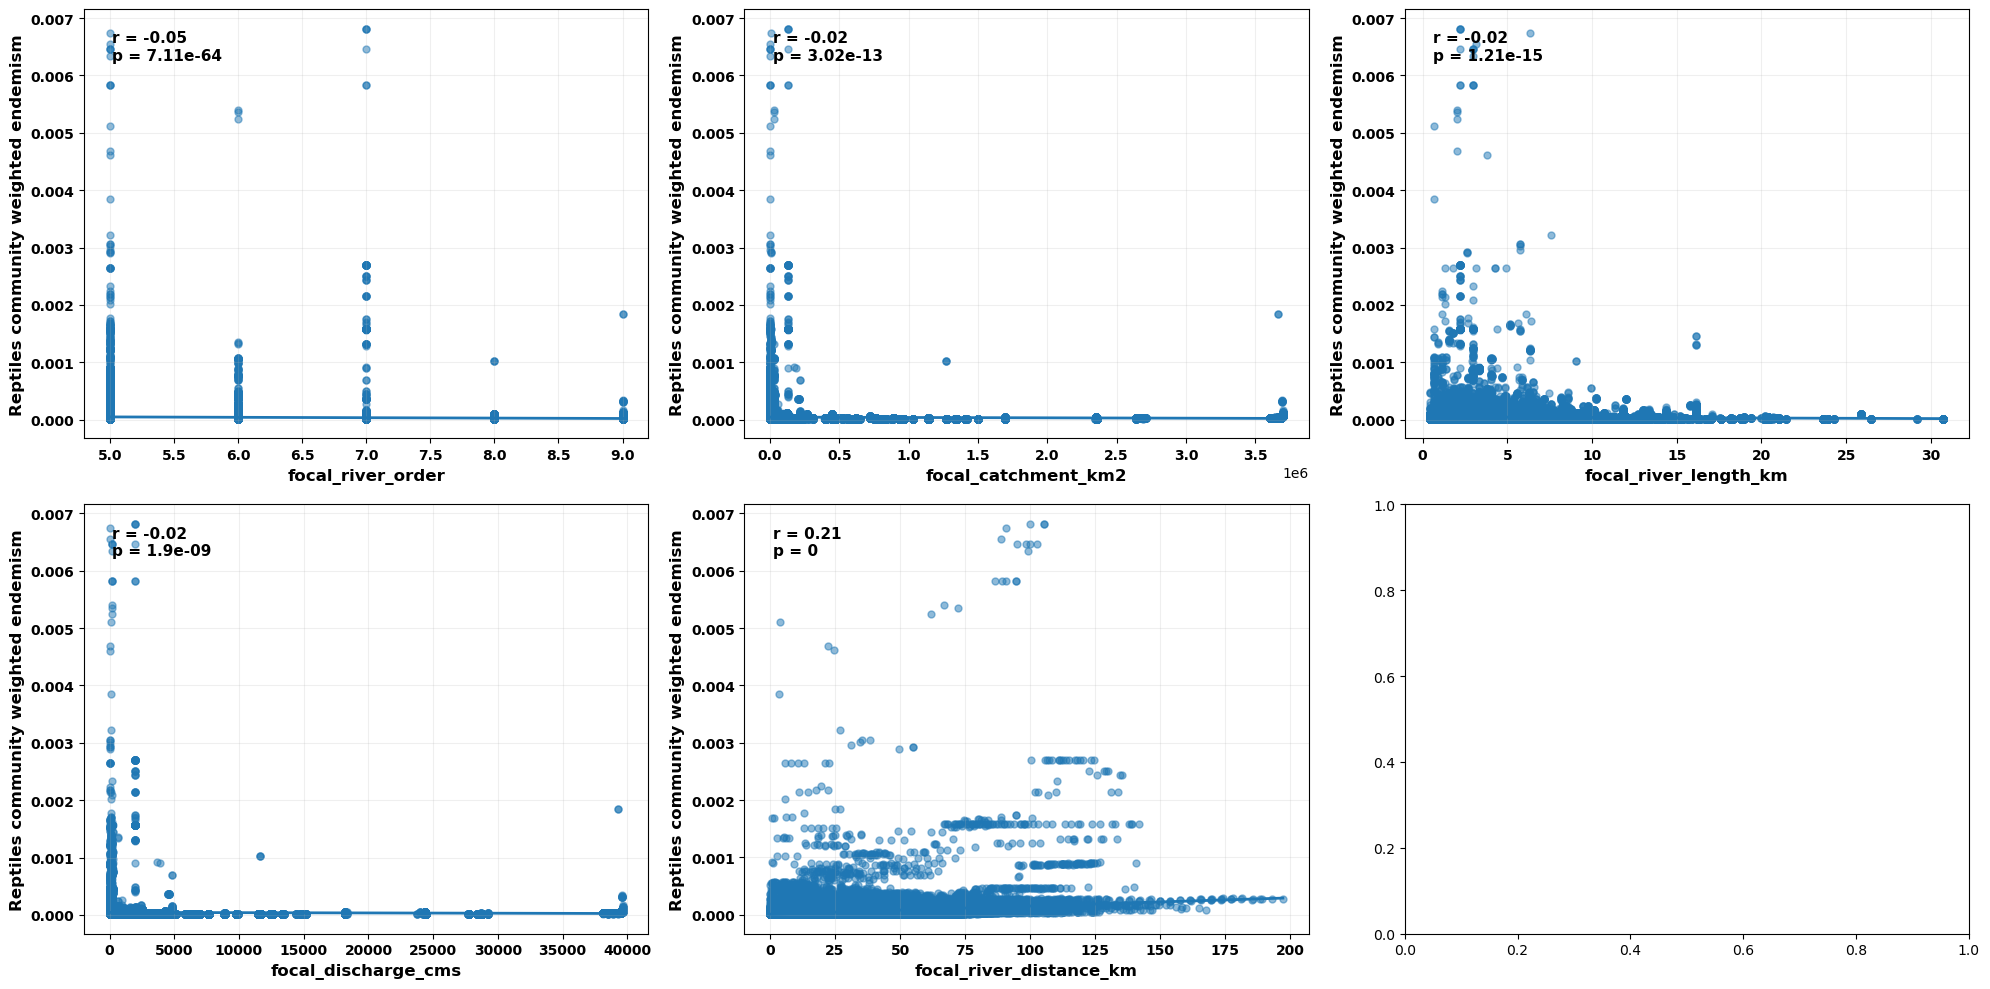

In [50]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import pearsonr

rivers_variables = {
    "ORD_STRA": "focal_river_order",
    "UPLAND_SKM": "focal_catchment_km2",
    "LENGTH_KM": "focal_river_length_km",
    "DIS_AV_CMS": "focal_discharge_cms",
    "distance_km": "focal_river_distance_km"
}

taxon_dataset=[birds, mammals, amphibians, reptiles]
label_t = ["Birds", "Mammals", "Amphibians", "Reptiles"]

for index, taxon in enumerate(taxon_dataset):
    fig, axes = plt.subplots(2,3, figsize=(20,10))
    axes = axes.flatten()
    
    for ax, (variable, label) in zip(axes, rivers_variables.items()):
        # Removing missing value
        data = taxon[["CWE", variable]].dropna()
        x = data[variable]
        y = data["CWE"]
        
        # Scatter plot
        ax.scatter(x,y, alpha=0.5, s=25)
        # Regression line
        if len(data)>1:
            slope, intercept = np.polyfit(x,y,1)
            x_line = np.linspace(x.min(), x.max(), 100)
            y_line = slope * x_line + intercept
            ax.plot(x_line, y_line, linewidth=2)
            # Pearson correlation
            r, p = pearsonr(x, y)
            ax.text(0.05,0.95,f"r = {r:.2f}\np = {p:.3g}",transform=ax.transAxes,verticalalignment="top",fontweight="bold",fontsize=11)
            
        # Bold axis labels
        ax.set_xlabel(label,fontweight="bold",fontsize=12)
        ax.set_ylabel(label_t[index]+" community weighted endemism",fontweight="bold",fontsize=12)

        # Bold tick labels
        ax.tick_params(axis="both", labelsize=10)

        for tick in ax.get_xticklabels():
            tick.set_fontweight("bold")

        for tick in ax.get_yticklabels():
            tick.set_fontweight("bold")

        ax.grid(alpha=0.2)

    plt.tight_layout()
    # Save as high-resolution PNG
    plt.savefig(label_t[index]+"_community_weighted_endemism_river_relationships.png",dpi=300,bbox_inches="tight")
    plt.show()